In [1]:
import os
# import torch
# from torch.utils.data import TensorDataset
# from torch.utils.data import DataLoader
# import torch.nn.functional as F
# from torchsummary import summary
from scipy.stats import gaussian_kde
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import h5py
import timeit
import scipy.linalg as spl
from scipy.stats import gaussian_kde
import scipy

import matplotlib
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

matplotlib.rc('font', **font)
rl2e_y = lambda yest, yref : spl.norm(yest - yref, 2) / spl.norm(yref, 2)

In [147]:
pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

In [2]:
def eigenpairs(x):
    meanx = np.mean(x,axis=1)
    cov = np.cov(x)
    lam,Phi = np.linalg.eigh(cov+np.sqrt(np.finfo(float).eps) * np.eye(cov.shape[0]))
    idx = lam.argsort()[::-1]
    lamx = lam[idx]
    Phix = Phi[:,idx]
    Psix = Phix @ np.diag(np.sqrt(lamx))
    return meanx, lamx, Psix

In [3]:

np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realizations.nc')['k33'].values[:])[0,:,:,10] # k for horizonal; k33 for vertical

array([[-2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443],
       [-2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443],
       [-2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443],
       [-2.69229443, -2.69229443, -2.69229443, -2.69229443, -2.69229443,
        -2.69229443, -2.69229443, -2.69229443, -

In [9]:
y_ref_noisy = np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_kh_head_pest_IES_1176mem_4iss_truth_realistic_ensemble_noisy_head_100.0.nc')['kh'].values[:])
h_ref_noisy = xr.open_dataset('data/newdata/freyberg_tv_3d_kh_head_pest_IES_1176mem_4iss_truth_realistic_ensemble_noisy_head_100.0.nc')['head'].values[:]
print(y_ref_noisy.shape)
print(h_ref_noisy.shape)
pest_k = np.mean(y_ref_noisy[:,:,:,3,:],axis=3)
pest_k_std = np.std(y_ref_noisy[:,:,:,3,:],axis=3)
print(pest_k.shape)
print(pest_k_std.shape)


(3, 40, 20, 4, 1176)
(25, 3, 40, 20, 4, 1176)
(3, 40, 20)
(3, 40, 20)


## Estimated heads from the ModFlow

In [10]:
heads_kle = xr.open_dataset('New_results/heads_from_k_samples_kle.nc')['heads'].values[:] 
print(heads_kle.shape)
heads_nokle = xr.open_dataset('New_results/heads_from_k_samples_no_kle.nc')['heads'].values[:] 
print(heads_nokle.shape)
heads_pest = xr.open_dataset('data/newdata/freyberg_tv_3d_kh_head_pest_IES_1176mem_4iss_truth_realistic_ensemble_noisy_head_100.0.nc')['head'].values[:] 
heads_pest = heads_pest[:,:,:,:,-1,:] # the last iteration
print(heads_pest.shape)

(25, 3, 40, 20, 2000)
(25, 3, 40, 20, 2000)
(25, 3, 40, 20, 1176)


In [11]:
heads_pest1 = xr.open_dataset('data/newdata/freyberg_tv_3d_kh_head_pest_IES_1176mem_4iss_truth_realistic_base_realizations_noisy_head_100.0.nc')['head'].values[:]
heads_pest1 = heads_pest1[:,:,:,:,-1] # the last iteration
print(heads_pest1.shape)
# heads_pest1-np.mean(heads_pest,axis=4)

(25, 3, 40, 20)


In [26]:
##### With KLE
heads_kle_partial = heads_kle[:,:,mask_y,:][:,:,index,:]
print(heads_kle_partial.shape)

heads_kle_layer1 = heads_kle[:,0,mask_y,:][:,index,:]
print(heads_kle_layer1.shape)
heads_kle_layer2 = heads_kle[:,1,mask_y,:][:,index,:]
heads_kle_layer3 = heads_kle[:,2,mask_y,:][:,index,:]

##### No KLE
heads_nokle_partial = heads_nokle[:,:,mask_y,:][:,:,index,:]
print(heads_nokle_partial.shape)

heads_nokle_layer1 = heads_nokle[:,0,mask_y,:][:,index,:]
print(heads_kle_layer1.shape)
heads_nokle_layer2 = heads_nokle[:,1,mask_y,:][:,index,:]
heads_nokle_layer3 = heads_nokle[:,2,mask_y,:][:,index,:]

##### PEST
heads_pest_partial = heads_pest[:,:,mask_y,:][:,:,index,:]
print(heads_pest_partial.shape)

heads_pest_layer1 = heads_pest[:,0,mask_y,:][:,index,:]
print(heads_pest_layer1.shape)
heads_pest_layer2 = heads_pest[:,1,mask_y,:][:,index,:]
heads_pest_layer3 = heads_pest[:,2,mask_y,:][:,index,:]

##### Ground truth
head_true = h_tempt[:,:,-1]
print(head_true.shape)

(25, 3, 13, 2000)
(25, 13, 2000)
(25, 3, 13, 2000)
(25, 13, 2000)
(25, 3, 13, 1176)
(25, 13, 1176)
(25, 39)


## Plot figures

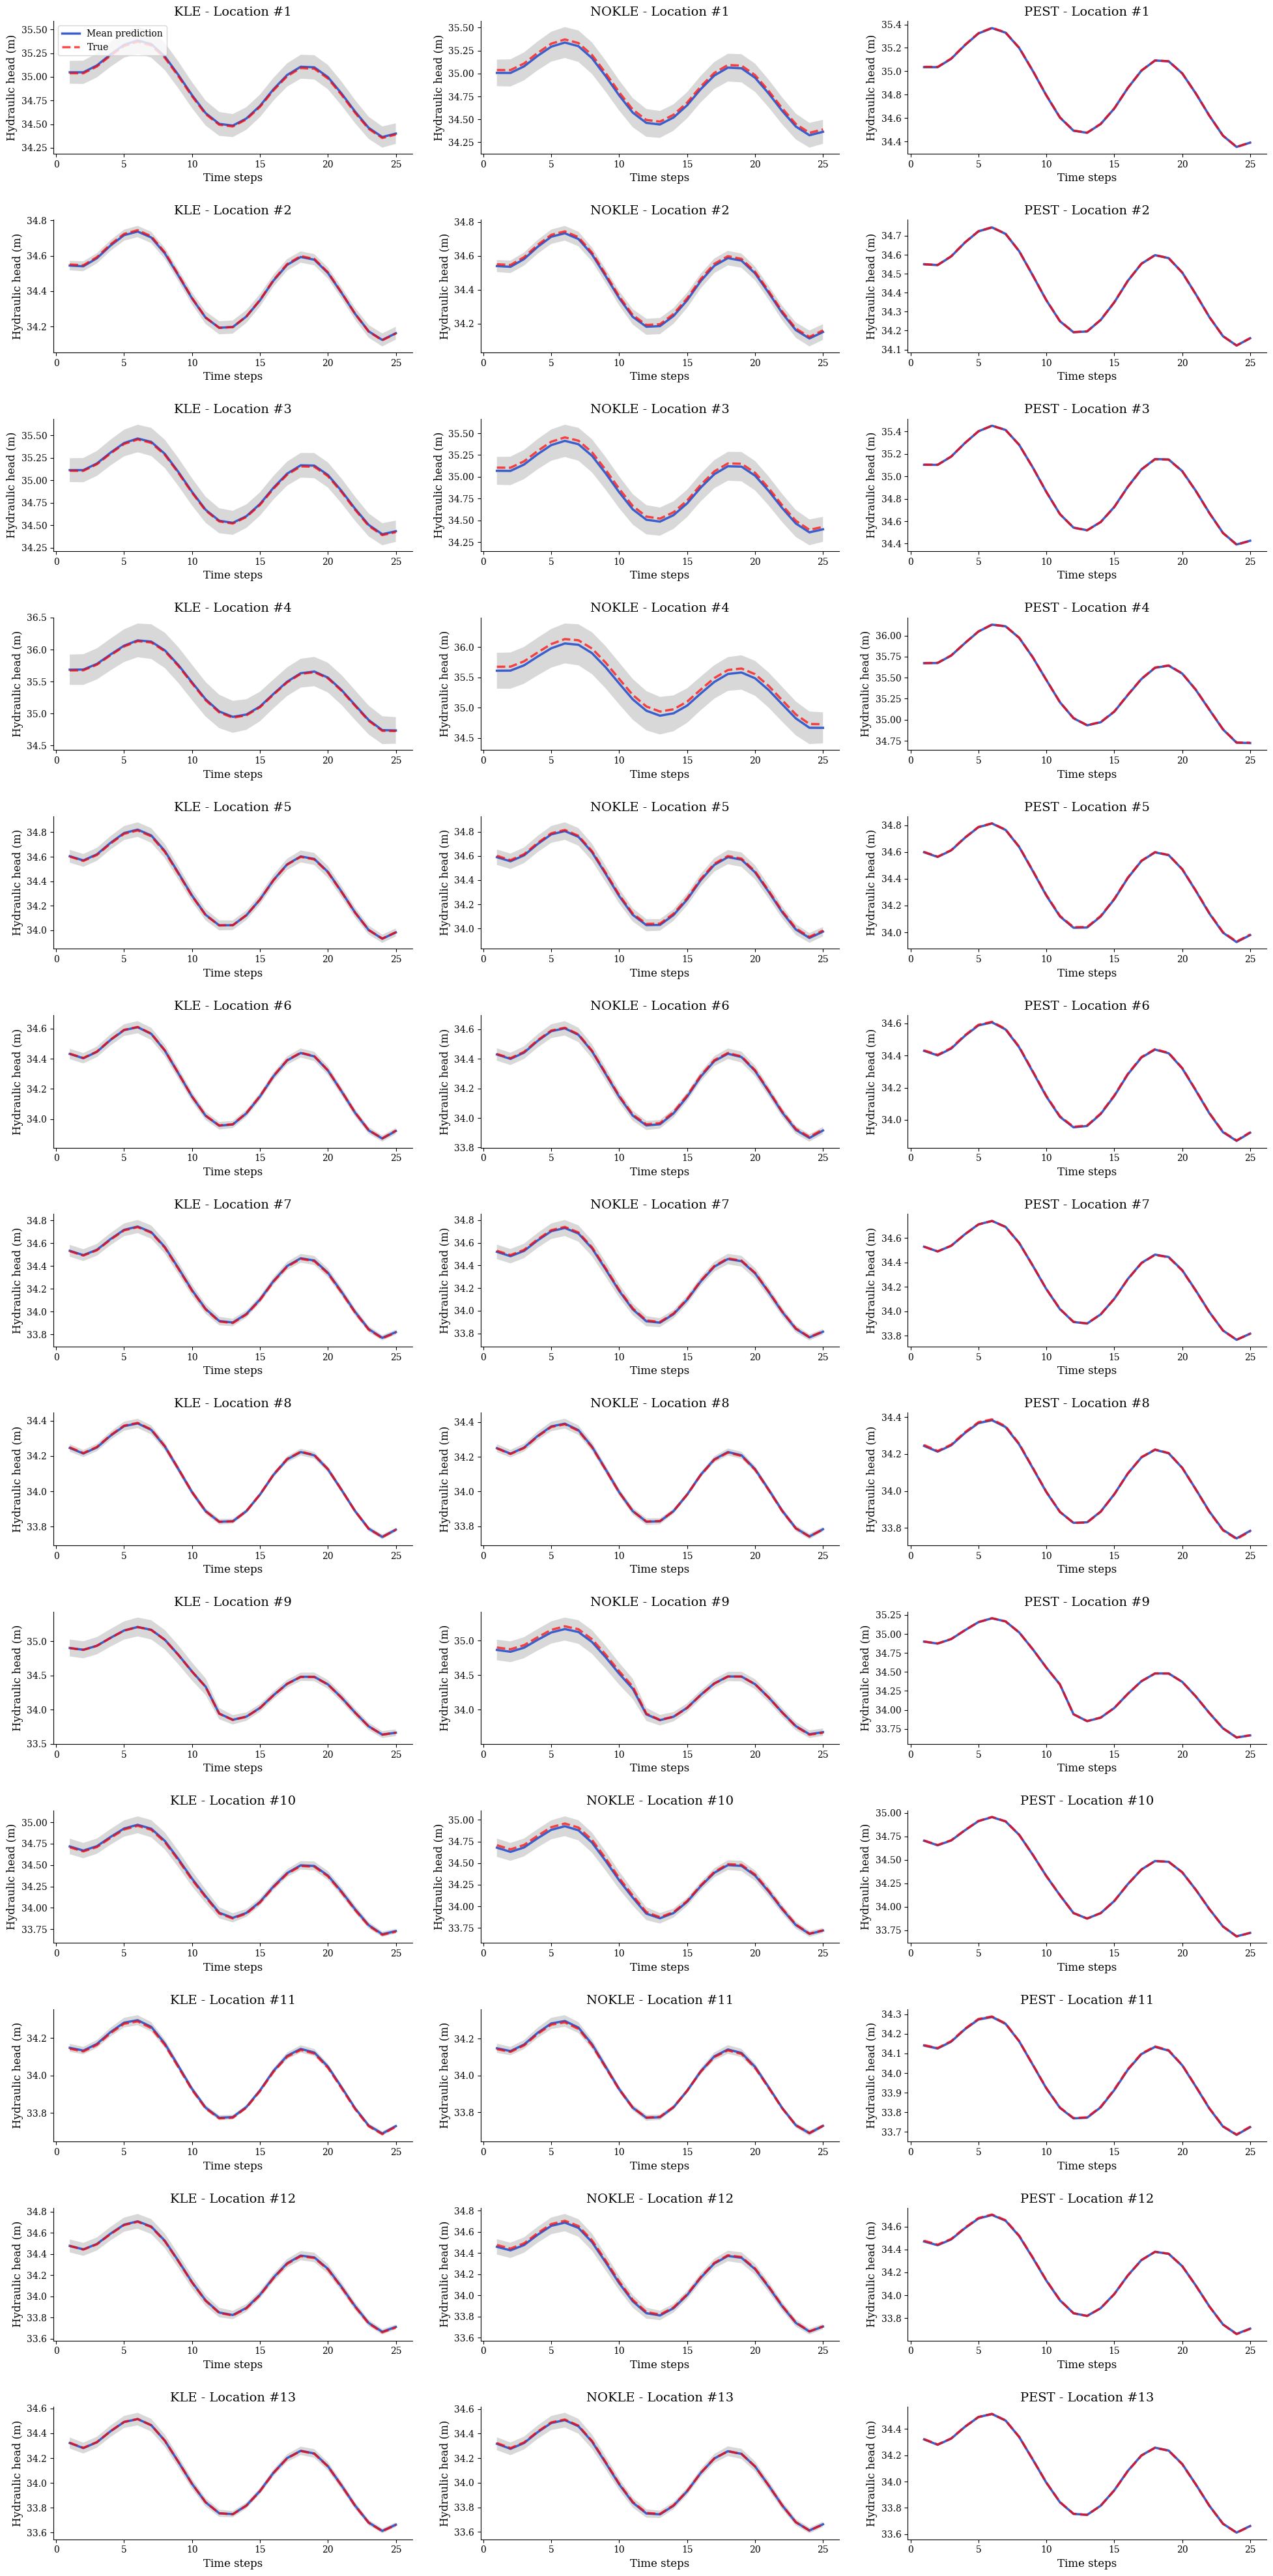

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Set the layer to analyze
layer = 0

# Compute mean and standard deviation for KLE, NOKLE, and PEST
pred_mean_kle = np.mean(heads_kle_partial[:, layer, :, :], axis=2)
pred_std_kle = np.std(heads_kle_partial[:, layer, :, :], axis=2)

pred_mean_nokle = np.mean(heads_nokle_partial[:, layer, :, :], axis=2)
pred_std_nokle = np.std(heads_nokle_partial[:, layer, :, :], axis=2)

pred_mean_pest = np.mean(heads_pest_partial[:, layer, :, :], axis=2)
pred_std_pest = np.std(heads_pest_partial[:, layer, :, :], axis=2)

# True values with added noise
true = head_true[:, :13] + 0 #np.random.normal(0, 0.01, (25, 13))

# Create a figure and subplots
f, axarr = plt.subplots(13, 3, figsize=(20, 40))  # 13 locations, 3 methods per location
f.subplots_adjust(hspace=0.5, wspace=0.3)  # Adjust spacing between plots

# Titles for each method
methods = ['KLE', 'NOKLE', 'PEST']

# Time steps
n_points_grid = np.arange(1, 26, 1)

# Plot for each location
for loc in range(13):  # Loop through 13 locations
    for col, (pred_mean, pred_std, method) in enumerate(zip(
        [pred_mean_kle, pred_mean_nokle, pred_mean_pest],
        [pred_std_kle, pred_std_nokle, pred_std_pest],
        methods
    )):
        var_mean = pred_mean[:, loc]
        var_std = pred_std[:, loc]
        true_t = true[:, loc]
        
        ax = axarr[loc, col]
        ax.plot(n_points_grid, var_mean, '#3A5FCD', label='Mean prediction', lw=2.5)
        ax.fill_between(
            n_points_grid,
            var_mean - 2 * var_std,
            var_mean + 2 * var_std,
            interpolate=True,
            facecolor='gray',
            alpha=0.3
        )
        ax.plot(n_points_grid, true_t, 'r--', label='True', lw=2.5, alpha=0.7)
        
        # Customize plot appearance
        ax.set_title(f'{method} - Location #{loc + 1}', fontsize=14)
        ax.set_xticks([0, 5, 10, 15, 20, 25])
        ax.set_ylabel('Hydraulic head (m)', fontsize=12)
        ax.set_xlabel('Time steps', fontsize=12)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.tick_params(labelsize=10)
        
        # Add legend to the first column only
        if loc == 0 and col == 0:
            ax.legend(loc='upper left', fontsize=10)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


/var/folders/x4/zwvf8_gn4kv9m8th8jw6cfsw0000gn/T/ipykernel_12515/1517866648.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  viridis = cm.get_cmap('viridis', 4)  # Generate 4 distinct colors


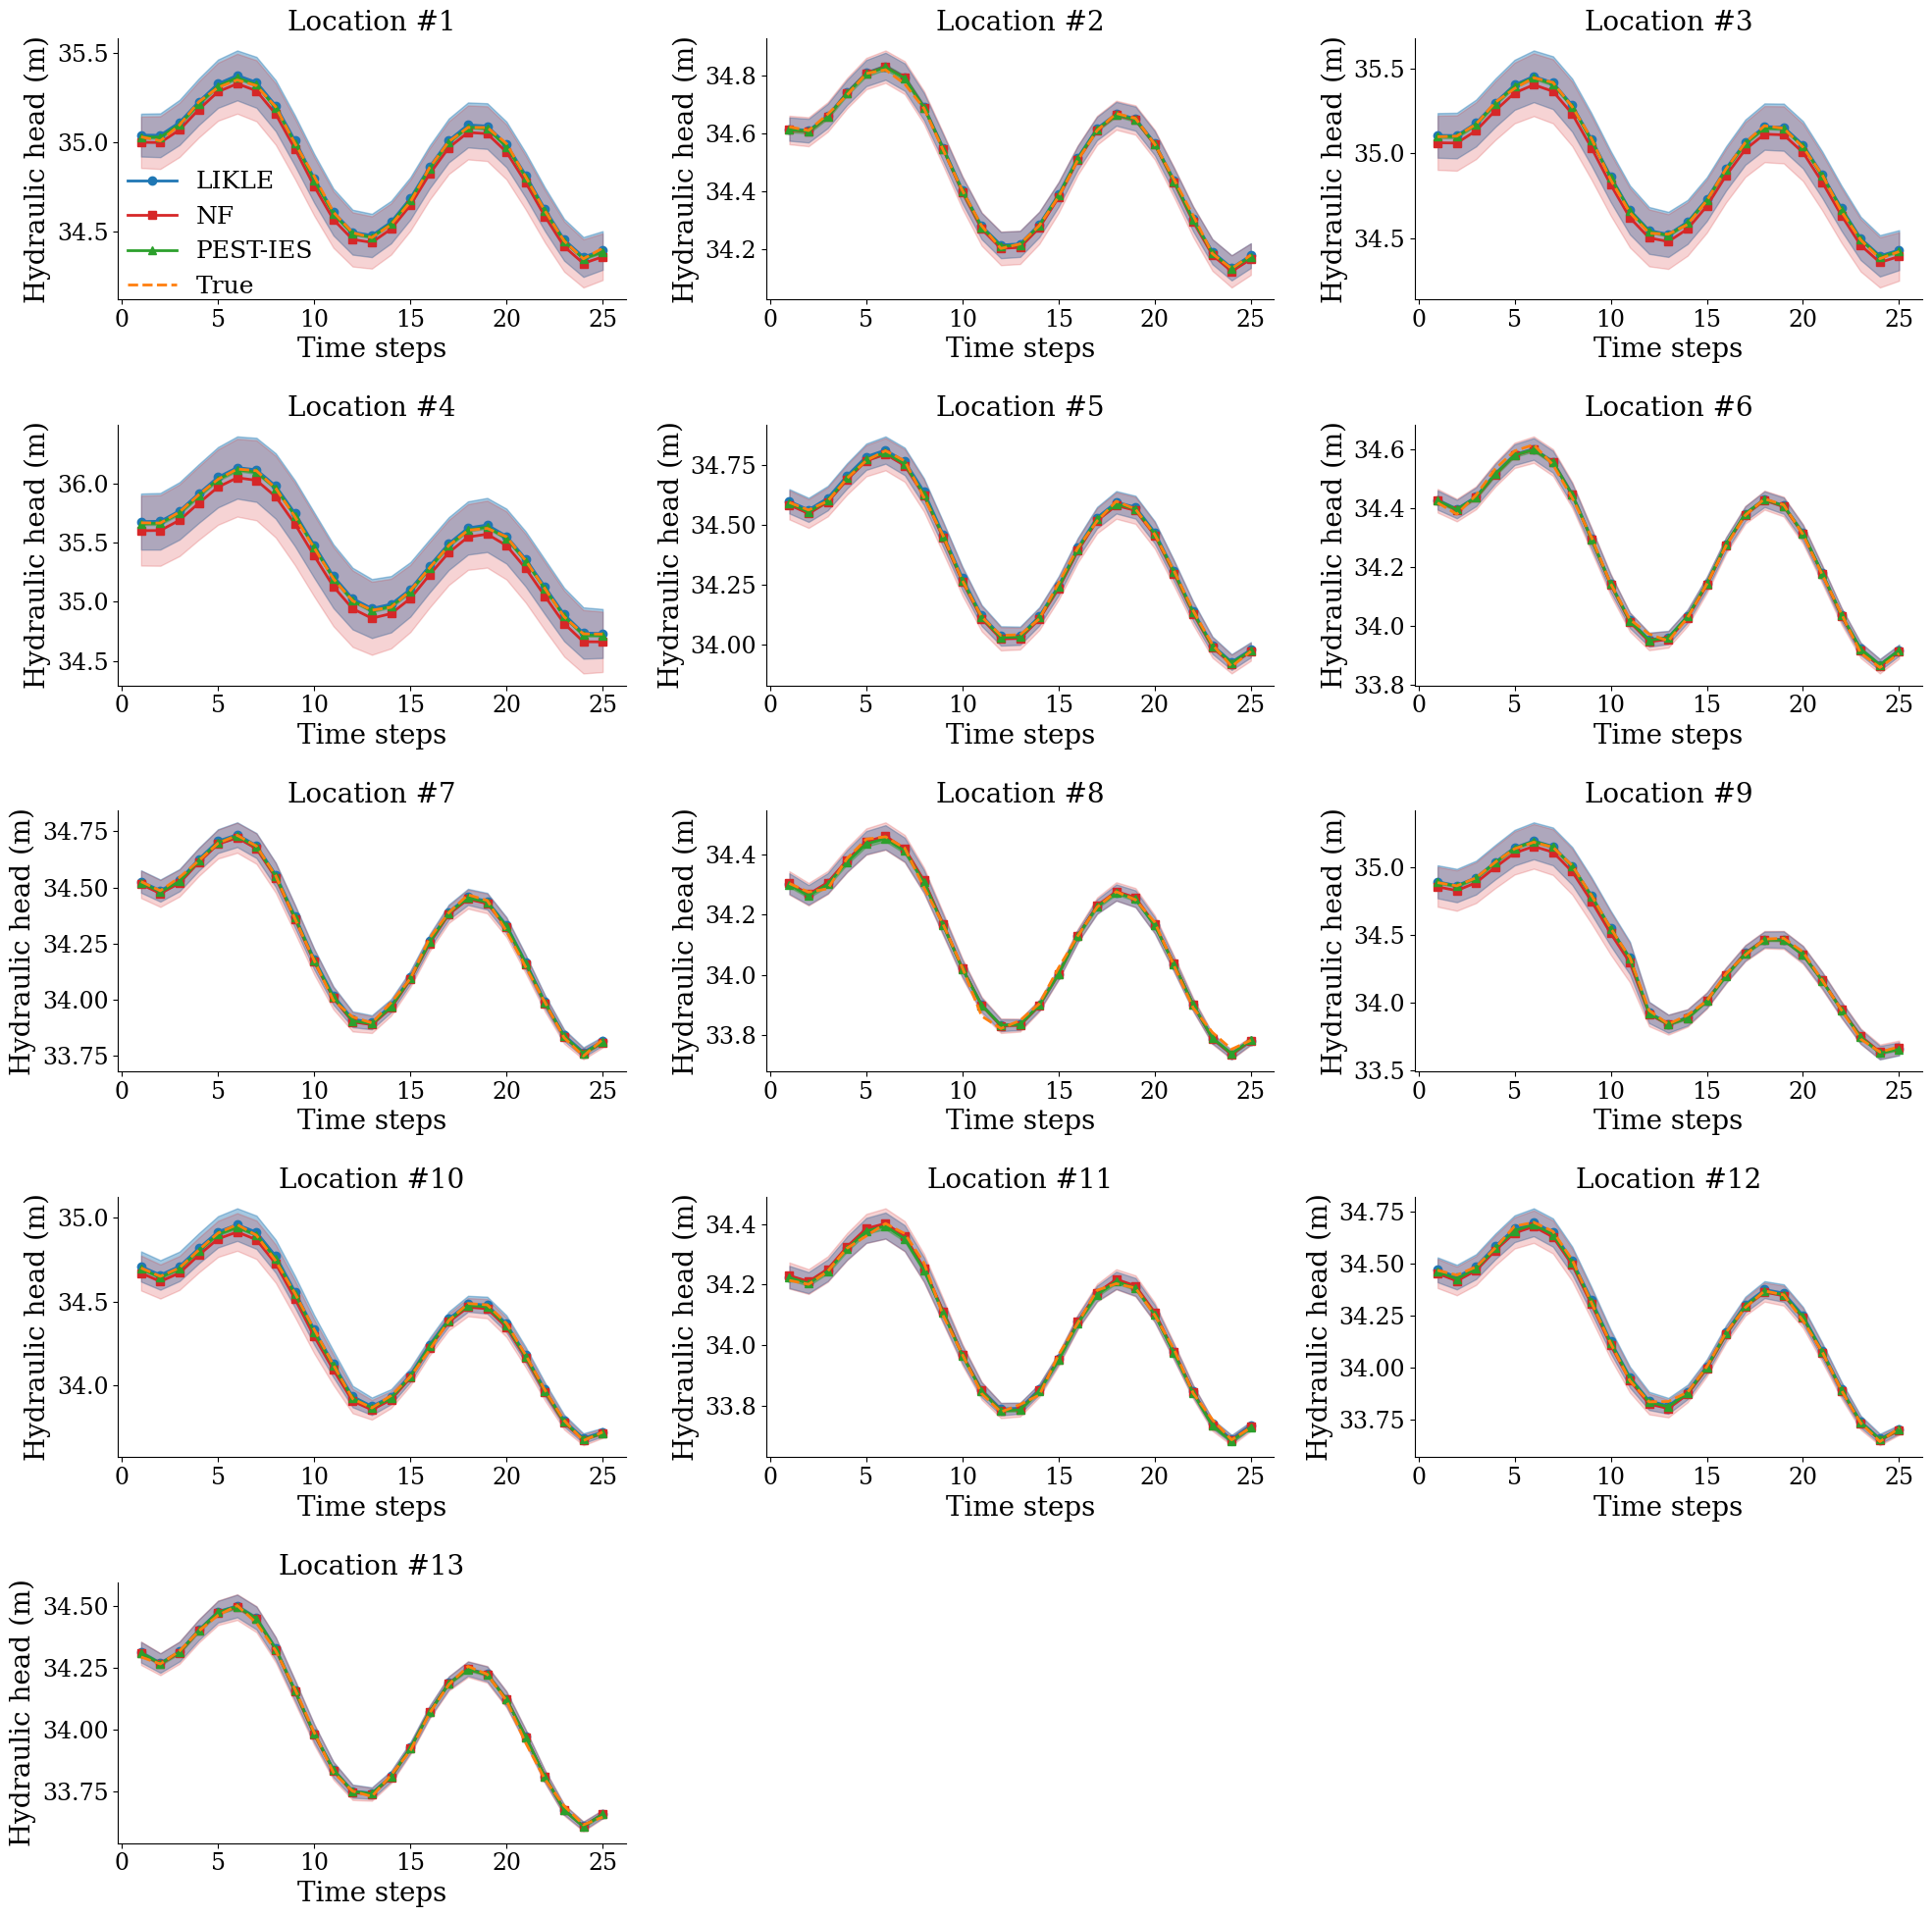

In [200]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
# Set the layer to analyze
layer = 2

# Compute mean and standard deviation for KLE, NOKLE, and PEST
pred_mean_kle = np.mean(heads_kle_partial[:, layer, :, :], axis=2)
pred_std_kle = np.std(heads_kle_partial[:, layer, :, :], axis=2)

pred_mean_nokle = np.mean(heads_nokle_partial[:, layer, :, :], axis=2)
pred_std_nokle = np.std(heads_nokle_partial[:, layer, :, :], axis=2)

pred_mean_pest = np.mean(heads_pest_partial[:, layer, :, :], axis=2)
pred_std_pest = np.std(heads_pest_partial[:, layer, :, :], axis=2)

# True values with added noise
true = head_true[:, 13*layer:13*(layer+1)] + np.random.normal(0, 0.01, (25, 13))

# Create a figure and subplots
f, axarr = plt.subplots(5, 3, figsize=(20, 20))  # 5x3 grid for 13 subplots
axarr = axarr.flat  # Flatten to access subplots easily
f.subplots_adjust(hspace=0.4, wspace=0.3)

# Time steps
n_points_grid = np.arange(1, 26, 1)

# Colors and markers for each method
viridis = cm.get_cmap('viridis', 4)  # Generate 4 distinct colors
# methods = {
#     'LICKLE': {'color': viridis(0), 'marker': 'o', 'label': 'LICKLE'},  # Blue
#     'NF': {'color': viridis(1), 'marker': 's', 'label': 'NF'},  # Red
#     'PEST-IES': {'color': viridis(2), 'marker': '^', 'label': 'PEST-IES'},  # Green
#     'True': {'color': viridis(3), 'linestyle': '--', 'label': 'True'}  # Orange
# }

methods = {
    'LICKLE': {'color': '#1f77b4', 'marker': 'o', 'label': 'LIKLE'},  # Blue
    'NF': {'color': '#d62728', 'marker': 's', 'label': 'NF'},  # Red
    'PEST-IES': {'color': '#2ca02c', 'marker': '^', 'label': 'PEST-IES'},  # Green
    'True': {'color': '#ff7f0e', 'linestyle': '--', 'label': 'True'}  # Orange
}

marker_size =6
# Plot for each location
for loc in range(13):
    ax = axarr[loc]
    
    # KLE predictions
    var_mean_kle = pred_mean_kle[:, loc]
    var_std_kle = pred_std_kle[:, loc]
    ax.plot(n_points_grid, var_mean_kle, color=methods['LICKLE']['color'], 
            marker=methods['LICKLE']['marker'], label=methods['LICKLE']['label'], lw=2,
           markersize = marker_size)
    ax.fill_between(n_points_grid, var_mean_kle - 2 * var_std_kle, 
                    var_mean_kle + 2 * var_std_kle, color=methods['LICKLE']['color'], alpha=0.4)
    
    # NOKLE predictions
    var_mean_nokle = pred_mean_nokle[:, loc]
    var_std_nokle = pred_std_nokle[:, loc]
    ax.plot(n_points_grid, var_mean_nokle, color=methods['NF']['color'], 
            marker=methods['NF']['marker'], label=methods['NF']['label'], lw=2,
markersize = marker_size )
    ax.fill_between(n_points_grid, var_mean_nokle - 2 * var_std_nokle, 
                    var_mean_nokle + 2 * var_std_nokle, color=methods['NF']['color'], alpha=0.2)
    
    # PEST predictions
    var_mean_pest = pred_mean_pest[:, loc]
    var_std_pest = pred_std_pest[:, loc]
    ax.plot(n_points_grid, var_mean_pest, color=methods['PEST-IES']['color'], 
            marker=methods['PEST-IES']['marker'], label=methods['PEST-IES']['label'], lw=2,
           markersize = marker_size )
    ax.fill_between(n_points_grid, var_mean_pest - 2 * var_std_pest, 
                    var_mean_pest + 2 * var_std_pest, color=methods['PEST-IES']['color'], alpha=0.4)
    
    # True values
    true_t = true[:, loc]
    ax.plot(n_points_grid, true_t, color=methods['True']['color'], 
            linestyle=methods['True']['linestyle'], label=methods['True']['label'], lw=2,
           markersize =marker_size )
    
    # Customize subplot appearance
    ax.set_title(f'Location #{loc + 1}', fontsize=20)
    ax.set_xticks([0, 5, 10, 15, 20, 25])
    ax.set_ylabel('Hydraulic head (m)', fontsize=20)
    ax.set_xlabel('Time steps', fontsize=20)
    ax.tick_params(labelsize=17)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    # Add legend to the first subplot only
    if loc == 0:
        ax.legend(loc='lower left', fontsize=18,frameon=False,bbox_to_anchor=(-0.025, -0.08))

# Hide any extra subplots
for i in range(13, len(axarr)):
    axarr[i].axis('off')


# Adjust layout and show the plot
plt.tight_layout()
plt.show()


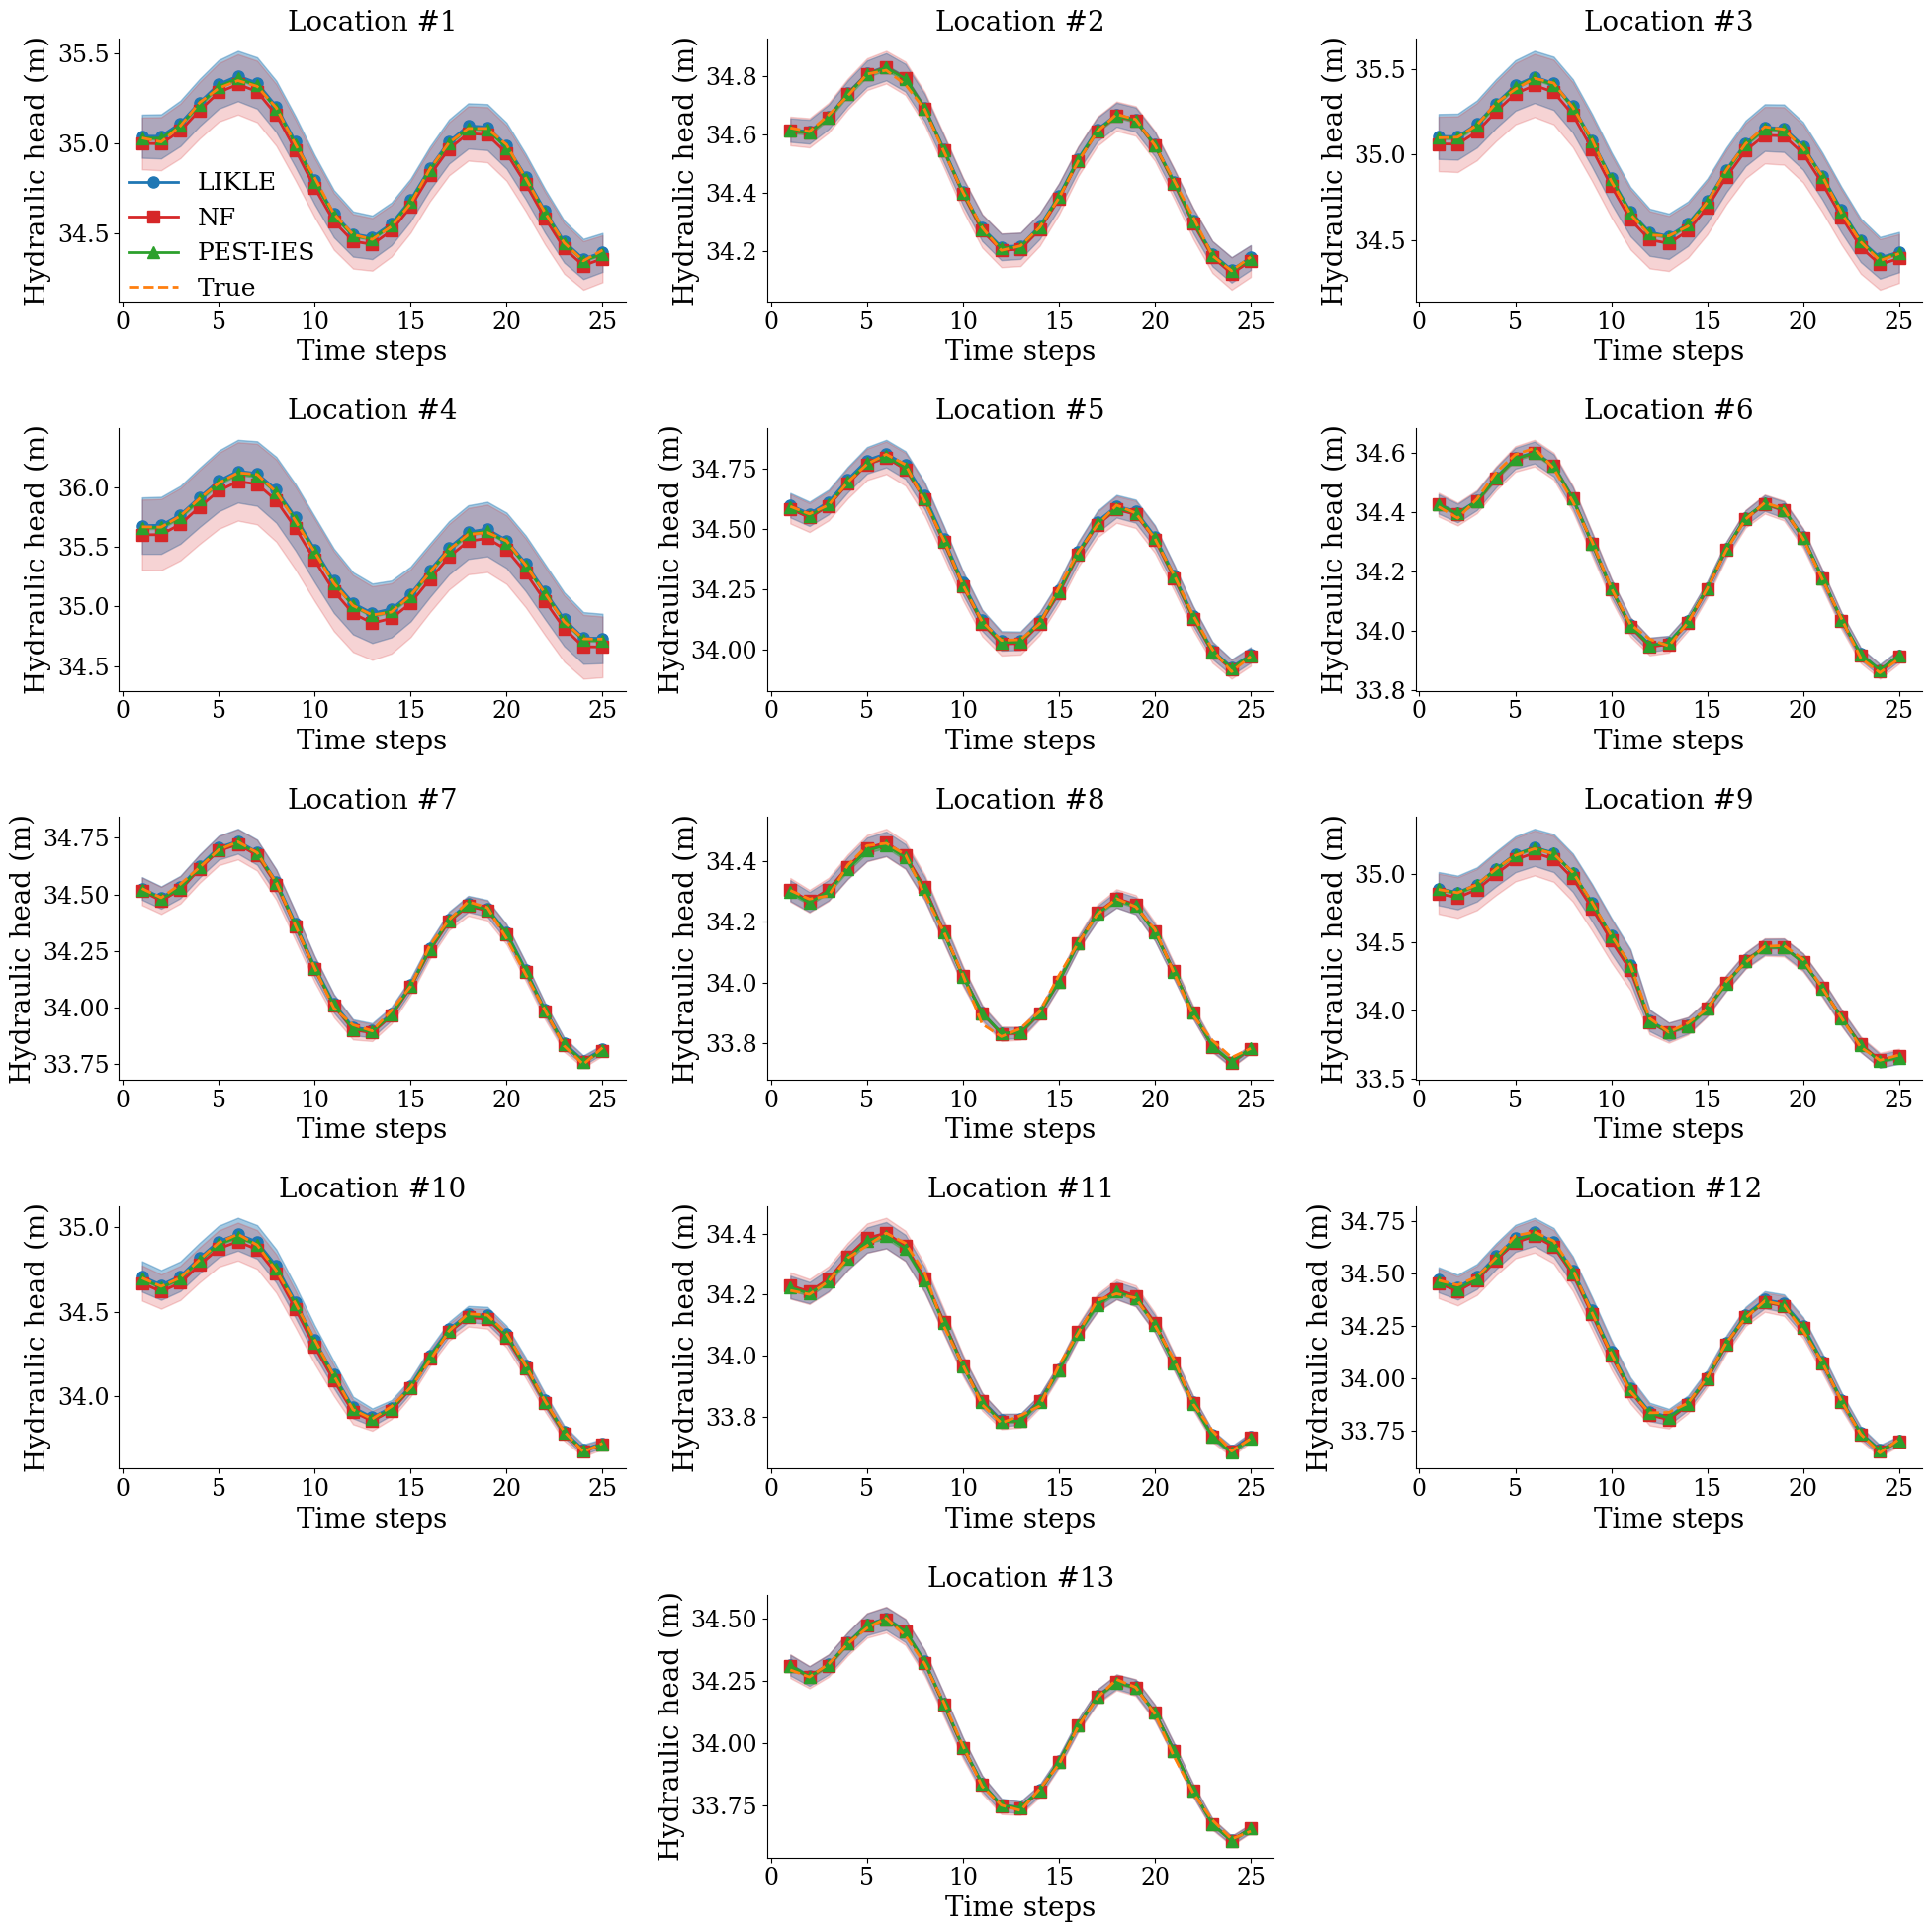

In [201]:
import matplotlib.gridspec as gridspec

# Create a figure and grid layout
f = plt.figure(figsize=(20, 20))
gs = gridspec.GridSpec(5, 3, figure=f)  # 5x3 grid layout

# Create subplots
axarr = []
for loc in range(13):
    if loc < 12:
        axarr.append(f.add_subplot(gs[loc // 3, loc % 3]))  # Regular placement
    else:
        axarr.append(f.add_subplot(gs[4, 1]))  # Center the last subplot in the last row

# Time steps and marker size
n_points_grid = np.arange(1, 26, 1)
marker_size = 8

# Plot for each location
for loc, ax in enumerate(axarr):
    if loc >= 13:  # Skip extra subplots
        continue
    
    # KLE predictions
    var_mean_kle = pred_mean_kle[:, loc]
    var_std_kle = pred_std_kle[:, loc]
    ax.plot(n_points_grid, var_mean_kle, color=methods['LICKLE']['color'], 
            marker=methods['LICKLE']['marker'], label=methods['LICKLE']['label'], lw=2,
           markersize = marker_size)
    ax.fill_between(n_points_grid, var_mean_kle - 2 * var_std_kle, 
                    var_mean_kle + 2 * var_std_kle, color=methods['LICKLE']['color'], alpha=0.4)
    
    # NOKLE predictions
    var_mean_nokle = pred_mean_nokle[:, loc]
    var_std_nokle = pred_std_nokle[:, loc]
    ax.plot(n_points_grid, var_mean_nokle, color=methods['NF']['color'], 
            marker=methods['NF']['marker'], label=methods['NF']['label'], lw=2,
    markersize = marker_size )
    ax.fill_between(n_points_grid, var_mean_nokle - 2 * var_std_nokle, 
                    var_mean_nokle + 2 * var_std_nokle, color=methods['NF']['color'], alpha=0.2)
    
    # PEST predictions
    var_mean_pest = pred_mean_pest[:, loc]
    var_std_pest = pred_std_pest[:, loc]
    ax.plot(n_points_grid, var_mean_pest, color=methods['PEST-IES']['color'], 
            marker=methods['PEST-IES']['marker'], label=methods['PEST-IES']['label'], lw=2,
           markersize = marker_size )
    ax.fill_between(n_points_grid, var_mean_pest - 2 * var_std_pest, 
                    var_mean_pest + 2 * var_std_pest, color=methods['PEST-IES']['color'], alpha=0.4)
    
    # True values
    true_t = true[:, loc]
    ax.plot(n_points_grid, true_t, color=methods['True']['color'], 
            linestyle=methods['True']['linestyle'], label=methods['True']['label'], lw=2,
           markersize =marker_size )
    
    # Customize subplot appearance
    ax.set_title(f'Location #{loc + 1}', fontsize=20)
    ax.set_xticks([0, 5, 10, 15, 20, 25])
    ax.set_ylabel('Hydraulic head (m)', fontsize=20)
    ax.set_xlabel('Time steps', fontsize=20)
    ax.tick_params(labelsize=17)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    

# Add legend to the first subplot only
# axarr[0].legend(loc='upper left', fontsize=18,frameon=False)
    if loc == 0:
        ax.legend(loc='lower left', fontsize=18,frameon=False,bbox_to_anchor=(-0.025, -0.08))


# Adjust layout and show the plot
plt.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "bot_layer_heads.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()


## compare overall head accuracy

The overall L2 error_kle: 0.00019148166748040484
The overall L2 error_nokle: 0.0007147122539871468
The overall L2 error_pest: 5.9373136278817e-05


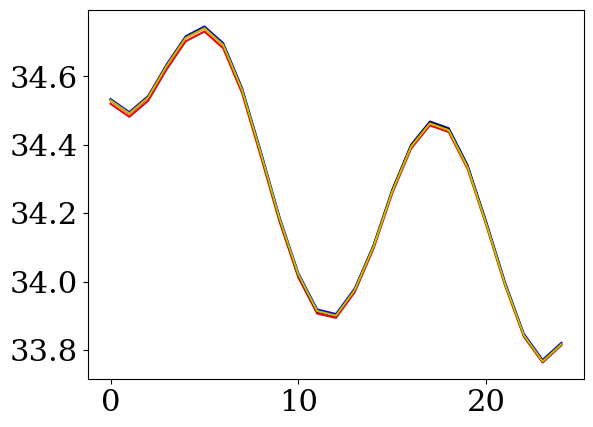

In [77]:
heads_kle_mean = np.mean(heads_kle_partial,axis=3).reshape(25,39)
heads_nokle_mean = np.mean(heads__nokle_partial,axis=3).reshape(25,39)
heads_pest_mean = np.mean(heads_pest_partial,axis=3).reshape(25,39)
pi=6
plt.plot(heads_kle_mean[:,pi],'b-')
plt.plot(heads_nokle_mean[:,pi],'r-')
plt.plot(heads_pest_mean[:,pi],'k-')
plt.plot(head_true[:,pi],'y-')

heads_kle_std = np.std(heads_kle_partial,axis=3).reshape(25,39)
heads_nokle_std = np.std(heads__nokle_partial,axis=3).reshape(25,39)
heads_pest_std = np.std(heads_pest_partial,axis=3).reshape(25,39)

# l2 error
# kle=np.mean(heads_kle[:,:,mask_y,:], axis=3).reshape(25,3*706)
# print(kle.shape)
# tem = h_all[:,:,:,:,-1][:,:,mask_y].reshape(25,3*706)
# print(tem.shape)

overall_error_kle = rl2e_y(heads_kle_mean,head_true)
overall_error_nokle = rl2e_y(heads_nokle_mean,head_true)
overall_error_pest = rl2e_y(heads_pest_mean,head_true)
print('The overall L2 error_kle:',overall_error_kle)
print('The overall L2 error_nokle:',overall_error_nokle)
print('The overall L2 error_pest:',overall_error_pest)



In [28]:
kle706=np.mean(heads_kle[:,:,mask_y,:], axis=3).reshape(25,3*706)
kle706_std=np.std(heads_kle[:,:,mask_y,:], axis=3).reshape(25,3*706)
print(kle.shape)

nokle706=np.mean(heads_nokle[:,:,mask_y,:], axis=3).reshape(25,3*706)
nokle706_std=np.std(heads_nokle[:,:,mask_y,:], axis=3).reshape(25,3*706)
print(nokle706.shape)

pest706 = np.mean(heads_pest[:,:,mask_y,:], axis=3).reshape(25,3*706)
pest706_std = np.std(heads_pest[:,:,mask_y,:], axis=3).reshape(25,3*706)
print(pest706.shape)

true706= h_all[:,:,:,:,-1][:,:,mask_y].reshape(25,3*706)
print(true706.shape)

overall_error_kle = rl2e_y(kle706,true706)
overall_error_nokle = rl2e_y(nokle706,true706)
overall_error_pest = rl2e_y(pest706,true706)
print('The overall L2 error_kle:',overall_error_kle)
print('The overall L2 error_nokle:',overall_error_nokle)
print('The overall L2 error_pest:',overall_error_pest)

NameError: name 'kle' is not defined

In [88]:
### evaluation for each layer
# layer_index = :706; 706:1412; -706:
overall_error_kle = rl2e_y(kle706[:,:706],true706[:,:706])
overall_error_nokle = rl2e_y(nokle706[:,:706],true706[:,:706])
overall_error_pest = rl2e_y(pest706[:,:706],true706[:,:706])
print('The overall L2 error_kle:',overall_error_kle)
print('The overall L2 error_nokle:',overall_error_nokle)
print('The overall L2 error_pest:',overall_error_pest)

The overall L2 error_kle: 0.00033176327267805977
The overall L2 error_nokle: 0.0008955728647545889
The overall L2 error_pest: 0.0002412183874583647


In [93]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

overall_lpp_kle = lpp_ens(kle706[:,-706:],kle706_std[:,-706:],true706[:,-706:])
overall_lpp_nokle = lpp_ens(nokle706[:,-706:],nokle706_std[:,-706:],true706[:,-706:])
overall_lpp_pest = lpp_ens(pest706[:,-706:],pest706_std[:,-706:],true706[:,-706:])
print('The overall lpp_kle:',overall_lpp_kle)
print('The overall lpp_nokle:',overall_lpp_nokle)
print('The overall lpp_pest:',overall_lpp_pest)

The overall lpp_kle: 44855.24631790264
The overall lpp_nokle: 41713.20296390462
The overall lpp_pest: 58917.20900139864


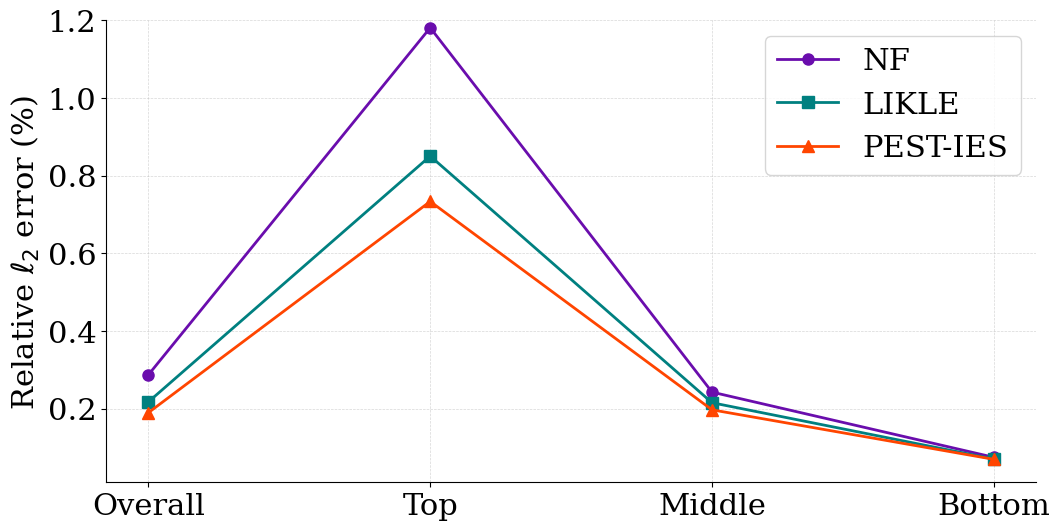

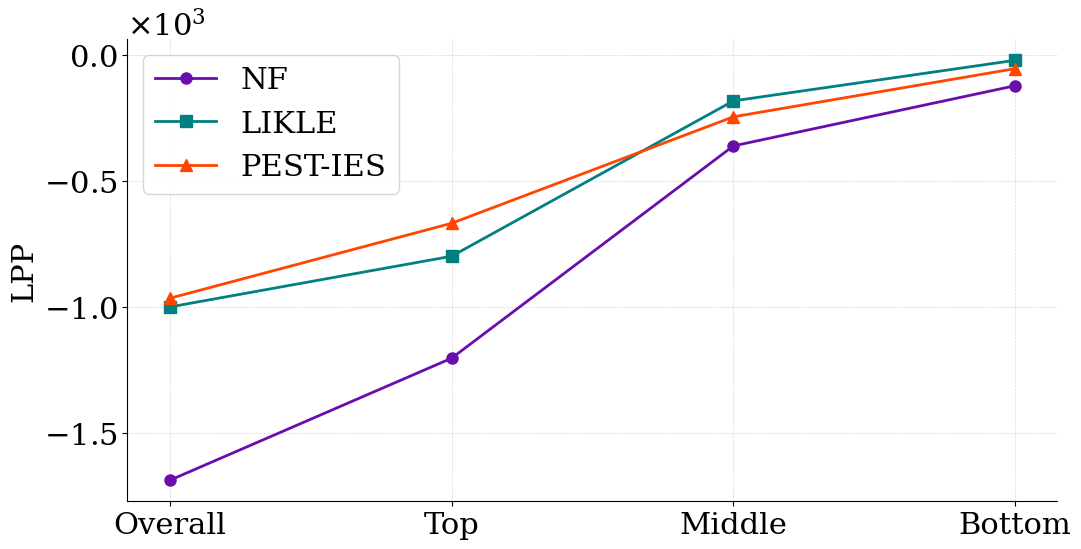

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Data extracted from the table
methods = ['NF', 'LIKLE', 'PEST-IES']
categories = ['Overall', 'Top', 'Middle', 'Bottom']

# Relative L2 error extracted from the image
relative_l2_error = np.array([
    [0.286827129, 1.180833724, 0.2422109373, 0.074295603],  # Without KLE
    [0.21715771, 0.8501941974, 0.214905185, 0.06996845353], # With KLE: LICKLE
    [0.1892938, 0.733322276, 0.1966204991, 0.06909870618]   # PEST
])

# LPP values extracted from the image
lpp = np.array([
    [-1685.68901, -1201.61857, -359.70076, -120.86475],   # Without KLE
    [-998.35859010, -797.20441065, -181.09163100, -20.06254843], # With KLE: LICKLE
    [-963.85534, -666.5402805, -244.2325024, -53.08256060] # PEST
])

# Define markers for each method
markers = ['o', 's', '^']
colors = ['#6a0dad', '#008080', '#ff4500'] 
marker_size = 8
# Plot Relative L2 Error
plt.figure(figsize=(12, 6))
for i, method in enumerate(methods):
    plt.plot(categories, relative_l2_error[i],color=colors[i],
             marker=markers[i], markersize=marker_size, 
             label=f'{method}', lw=2)

plt.ylim(0.01, 1.2) 
# plt.title('Comparison of Relative L2 Error')
plt.ylabel('Relative $\\ell_2$ error (%)')

# Remove upper and right spines
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend()
plt.grid(visible=True, linestyle='--', linewidth=0.5, alpha=0.5)
output_dir = "New_results"
output_path = os.path.join(output_dir, "l2_comparison_K.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

# Plot LPP
def yaxis_formatter(x, pos):
    return f'{int(x / 1e3)}'  # Divides the tick value by 1000
plt.figure(figsize=(12, 6))
for i, method in enumerate(methods):
    plt.plot(categories, lpp[i], marker=markers[i], color=colors[i],
             markersize=marker_size, 
             label=f'{method}', lw=2)


# plt.title('Comparison of LPP')
plt.ylabel('LPP')

# Remove upper and right spines
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
# Set scientific notation for y-axis
ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))  # Forces scientific notation

plt.legend()
plt.grid(visible=True, linestyle='--', linewidth=0.5, alpha=0.5)
output_dir = "New_results"
output_path = os.path.join(output_dir, "LPP_comparison_K.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()


In [ ]:
## plot figure for estimated K


In [15]:
# y_ref_mesh = np.log(xr.open_dataset('data/freyberg_tv_k_k33_head_realistic_truth.nc')['k'].values[:])
# h_ref_mesh = xr.open_dataset('data/freyberg_tv_k_k33_head_realistic_truth.nc')['head'].values[:]

# y_ens_mesh = np.log(xr.open_dataset('data/freyberg_tv_k_k33_head_realizations.nc')['k'].values[:])
# h_ens_mesh = xr.open_dataset('data/freyberg_tv_k_k33_head_realizations.nc')['head'].values[:]

### below is the new data with correct physics
y_ref_mesh = np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realistic_truth.nc')['k'].values[:])
h_ref_mesh = xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realistic_truth.nc')['head'].values[:]

y_ens_mesh = np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realizations.nc')['k'].values[:])
h_ens_mesh = xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realizations.nc')['head'].values[:]

print(y_ref_mesh.shape)
print(h_ref_mesh.shape)

print(y_ens_mesh.shape)
print(h_ens_mesh.shape)

mask = ~np.isnan(y_ens_mesh[0,:,:,0])

y_ref = y_ref_mesh[:,mask].T.flatten()
h_ref = h_ref_mesh[:,:,mask].T.flatten()

# y_toy = y_toy_mesh[:,mask].T.flatten()
# h_toy = h_toy_mesh[:,:,mask].T.flatten()

N_sample = y_ens_mesh.shape[-1]
y_ens = y_ens_mesh[:,mask,:].T.reshape((-1,N_sample))
h_ens = h_ens_mesh[:,:,mask,:].T.reshape((N_sample,-1)).T
print(y_ens.shape)
print(h_ens.shape)

NY_cells = y_ref.shape[0]
Nh_cells = h_ref.shape[0]


train_size = 5000
test_size = int(N_sample - train_size)


(3, 40, 20)
(25, 3, 40, 20)
(3, 40, 20, 5000)
(25, 3, 40, 20, 5000)
(2118, 5000)
(52950, 5000)


In [6]:
np.log(xr.open_dataset('data/freyberg_tv_k_k33_head_realizations.nc')['k33'].values[:])[2,:,:,9] # k for horizonal; k33 for vertical

array([[-1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275],
       [-1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275],
       [-1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275],
       [-1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -1.6666275, -1.6666275,
        -1.6666275, -1.6666275, -1.6666275, -

In [18]:
# y_ref_const = np.log(xr.open_dataset('data/freyberg_tv_k_k33_head_realistic_truth.nc')['k33'].values[:])
# y_ens_const = np.log(xr.open_dataset('data/freyberg_tv_k_k33_head_realizations.nc')['k33'].values[:])

y_ref_const = np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realistic_truth.nc')['k33'].values[:])
y_ens_const = np.log(xr.open_dataset('data/newdata/freyberg_tv_3d_k_k33_head_realizations.nc')['k33'].values[:])

y_all_const = np.concatenate([y_ens_const, y_ref_const.reshape([3,40,20,1])],axis=-1)
print(y_all_const.shape)
layer1_const=np.zeros([2,5001])
layer2_const=np.zeros([2,5001])
layer3_const=np.zeros([2,5001])
for i in range(5001):
    layer1_const[:,i]=np.unique(y_all_const[0,:,:,i])
    layer2_const[:,i]=np.unique(y_all_const[1,:,:,i])
    layer3_const[:,i]=np.unique(y_all_const[2,:,:,i])

y_constants = np.vstack([layer1_const[0,:],layer2_const[0,:],layer3_const[0,:]])
print(y_constants.shape)


(3, 40, 20, 5001)
(3, 5001)


In [19]:
y_all = np.concatenate([y_ens_mesh, y_ref_mesh.reshape([3,40,20,1])],axis=-1)
print(y_all.shape)

h_all = np.concatenate([h_ens_mesh, h_ref_mesh.reshape([25,3,40,20,1])],axis=-1)
print(h_all.shape)


(3, 40, 20, 5001)
(25, 3, 40, 20, 5001)


In [20]:
mask_y = ~np.isnan(y_ens_mesh[0,:,:,0])
y_all_y0 = y_all[0] # first layer
y_all_y1 = y_all[1] # second layer
y_all_y2 = y_all[2] # third layer

y_all_t0 = y_all_y0[mask_y,:]
y_all_t1 = y_all_y1[mask_y,:]
y_all_t2 = y_all_y2[mask_y,:]

y_tempt = np.vstack((y_all_t0,y_all_t1,y_all_t2))
print(y_tempt.shape)
y_withconst = np.vstack([y_tempt,y_constants])
print(y_withconst.shape)
# plt.hist(y_tempt[100,:],bins=50)

h_all_h0 = h_all[:,0,:,:]
h_all_h1 = h_all[:,1,:,:]
h_all_h2 = h_all[:,2,:,:]

h_all_t0 = h_all_h0[:,mask_y,:]
h_all_t1 = h_all_h1[:,mask_y,:]
h_all_t2 = h_all_h2[:,mask_y,:]
print(h_all_t2.shape)
h_tempt = np.concatenate((h_all_t0,h_all_t1,h_all_t2),axis=1)
print(h_tempt.shape)

directory_path = 'data/newdata'
# np.save(os.path.join(directory_path, 'New_parameters.npy'), y_tempt)
# np.save(os.path.join(directory_path, 'New_parameters_const.npy'), y_withconst)
# np.save(os.path.join(directory_path, 'New_hydraulic.npy'), h_tempt)


(2118, 5001)
(2121, 5001)
(25, 706, 5001)
(25, 2118, 5001)


In [22]:
mask_y = ~np.isnan(y_ens_mesh[0,:,:,0])
pest_y0 = pest_k[0] # first layer
pest_y1 = pest_k[1] # second layer
pest_y2 = pest_k[2] # third layer

pest_t0 = pest_y0[mask_y]
pest_t1 = pest_y1[mask_y]
pest_t2 = pest_y2[mask_y]

pestY_tempt = np.hstack((pest_t0,pest_t1,pest_t2))
print(pestY_tempt.shape)

pest_y0_std = pest_k_std[0] # first layer
pest_y1_std = pest_k_std[1] # second layer
pest_y2_std = pest_k_std[2] # third layer

pest_t0_std = pest_y0_std[mask_y]
pest_t1_std = pest_y1_std[mask_y]
pest_t2_std = pest_y2_std[mask_y]

pestY_tempt_std = np.hstack((pest_t0_std,pest_t1_std,pest_t2_std))
print(pestY_tempt_std.shape)

(2118,)
(2118,)


In [23]:
# This function is used to reconstruct y field from (706,) -> (40,20)
def mesh_recon_y(arr,i): # i is No.layer
    mesh = np.zeros(800)
    mesh[np.where(~np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = arr[706*i:706*(i+1)]
    mesh[np.where(np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = np.nan
    mesh = mesh.reshape((40,20))
    return mesh


# This function is used to reconstruct h field from (17650,) -> (25,40,20)
# def mesh_recon_h(arr,i):
#     mesh = np.zeros(40*20*25)
#     mesh[np.where(~np.isnan(h_ens_mesh[:,i,:,:,0].flatten()))[0]] = arr
#     mesh[np.where(np.isnan(h_ens_mesh[:,i,:,:,0].flatten()))[0]] = np.nan
#     mesh = mesh.reshape((25,40,20))
#     return mesh

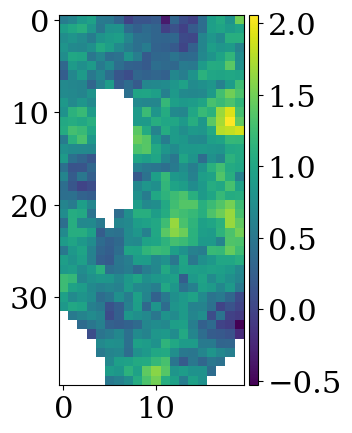

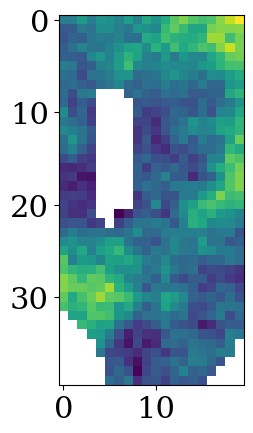

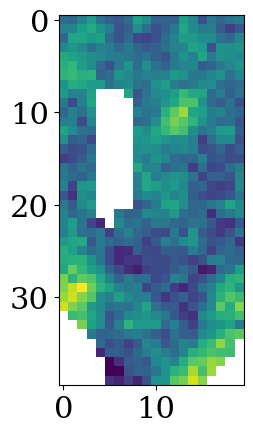

In [24]:
for i in range(5000,5001):
    ax = plt.subplot()
#     fig, axes = plt.subplots(1, 3, figsize=(19, 10))
    for j in range(3):
#         ax = axes[j]
        im=plt.imshow(mesh_recon_y(y_tempt[:,i],j))
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        plt.colorbar(im, cax=cax)
        plt.tight_layout()  
        plt.show()

In [25]:
# partial locations
index=np.array([ 49, 55, 68, 178, 247, 285, 377, 401, 430, 472, 541, 610, 630])
h_all_t0 = h_all_h0[:,mask_y,:][:,index,:]
h_all_t1 = h_all_h1[:,mask_y,:][:,index,:]
h_all_t2 = h_all_h2[:,mask_y,:][:,index,:]
print(h_all_t2.shape)
h_tempt = np.concatenate((h_all_t0,h_all_t1,h_all_t2),axis=1)
print(h_tempt.shape)
# np.save('hydraulic_partial.npy',h_tempt)
# np.save(os.path.join(directory_path, 'New_hydraulic_partial.npy'), h_tempt)

(25, 13, 5001)
(25, 39, 5001)


In [29]:
h_test = h_all[:,:,:,:,4900:5001]
y_test = y_all[:,:,:,4900:5001]

h_ref_mesh = h_test[:,:,:,:,-1]
y_ref_mesh = y_test[:,:,:,-1]
print(h_ref_mesh.shape)
print(y_ref_mesh.shape)

(25, 3, 40, 20)
(3, 40, 20)


In [30]:
print(h_ref_mesh[:,:,mask_y].shape)
# mask_y

(25, 3, 706)


In [31]:

# # Example data
# h = np.random.randn(25, 40, 20)  # Original data
# mask_y = ~np.isnan(h[0])  # Example mask for non-NaN values (assuming h[0] is representative)

# Apply mask to remove NaNs
h_cleaned = h_ref_mesh[:,0,:,:][:, mask_y] # first layer, other layers have the same observation locations

# Flatten original dimensions
flattened_indices = np.arange(40 * 20).reshape(40, 20)

# Apply the mask to get flattened indices without NaNs
filtered_indices = flattened_indices[mask_y]
print(filtered_indices)
# Locations of interest in the cleaned array
index = np.array([49, 55, 68, 178, 247, 285, 377, 401, 430, 472, 541, 610, 630])

# Map back to original 40x20 coordinates
original_positions = filtered_indices[index]

# Convert flattened positions back to 2D coordinates
original_coordinates = np.unravel_index(original_positions, (40, 20))

# Display the original coordinates
print(original_coordinates)


[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182
 183 188 189 190 191 192 193 194 195 196 197 198 199 200 201 202 203 208
 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223 228 229 230
 231 232 233 234 235 236 237 238 239 240 241 242 243 248 249 250 251 252
 253 254 255 256 257 258 259 260 261 262 263 268 26

[(2, 9), (2, 15), (3, 8), (9, 1), (13, 10), (15, 16), (21, 10), (22, 15), (24, 4), (26, 6), (29, 15), (33, 7), (34, 10)]
[0.03205128 0.03205128 0.17307692 1.01923077 1.58333333 1.86538462
 2.71153846 2.8525641  3.13461538 3.41666667 3.83974359 4.40384615
 4.54487179]


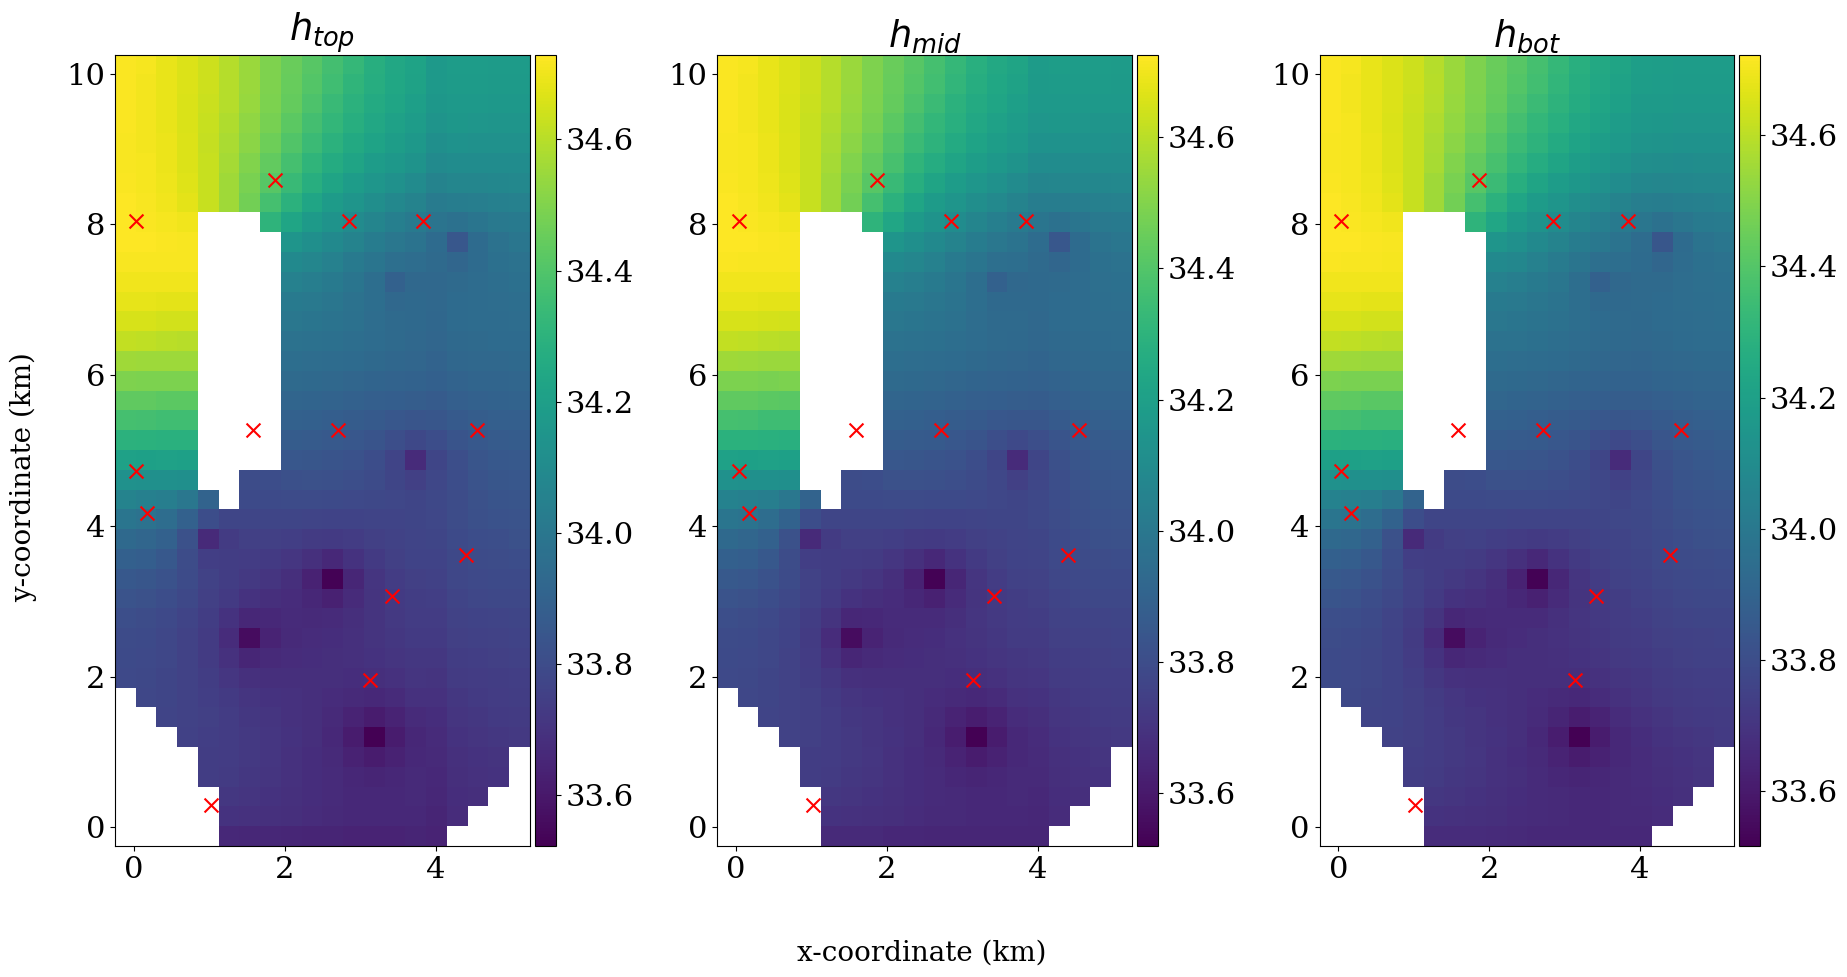

In [32]:
y_ref = y_ref_mesh[:,mask].flatten()
h_ref = h_ref_mesh[:,:,mask].flatten()

dx = 0.25
dy = 0.25
extent = [0-dx, 5+dx, 0-dy, 10+dy]
original_coordinates = (np.array([2, 2, 3, 9, 13, 15, 21, 22, 24, 26, 29, 33, 34]), 
                      np.array([9, 15, 8, 1, 10, 16, 10, 15, 4, 6, 15, 7, 10]))

h_min = h_ref.min()
h_max = h_ref.max()
fig,ax = plt.subplots(1,3,figsize=(19,10))
h0 = ax[0].imshow(h_ref_mesh[-1,0],extent=extent)
h1 = ax[1].imshow(h_ref_mesh[-1,1],extent=extent)
h2 = ax[2].imshow(h_ref_mesh[-1,2],extent=extent)

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
fig.colorbar(h0, cax=cax0)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
fig.colorbar(h1, cax=cax1)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes("right", size="5%", pad=0.05)
fig.colorbar(h2, cax=cax2)

fig.supxlabel('x-coordinate (km)',size = 20)
fig.supylabel('y-coordinate (km)',size = 20)

ax[0].set_title('$h_{top}$')
ax[1].set_title('$h_{mid} $')
ax[2].set_title('$h_{bot} $')

original_mask = ~np.isnan(h_ref_mesh[-1, 0])  # Assuming first channel's mask represents valid data

# Filter valid positions
valid_positions = []
for x, y in zip(*original_coordinates):
    if original_mask[x, y]:
        valid_positions.append((x, y))
        
x_extent = np.linspace(extent[0], extent[1], 40)  # Corresponds to 20 columns
y_extent = np.linspace(extent[2], extent[3], 20)  # Corresponds to 40 rows
print(valid_positions)
if valid_positions:
    valid_positions = np.array(valid_positions)
    x_positions = x_extent[valid_positions[:, 0]]
    y_positions = y_extent[valid_positions[:, 1]]
else:
    x_positions = []
    y_positions = []
print(x_positions)
# Plotting the markers ensuring they are valid
for i in range(3):
    ax[i].scatter(x_positions, y_positions, c='red', marker='x', s=100, label='Interest Points')

fig.tight_layout()
plt.show()

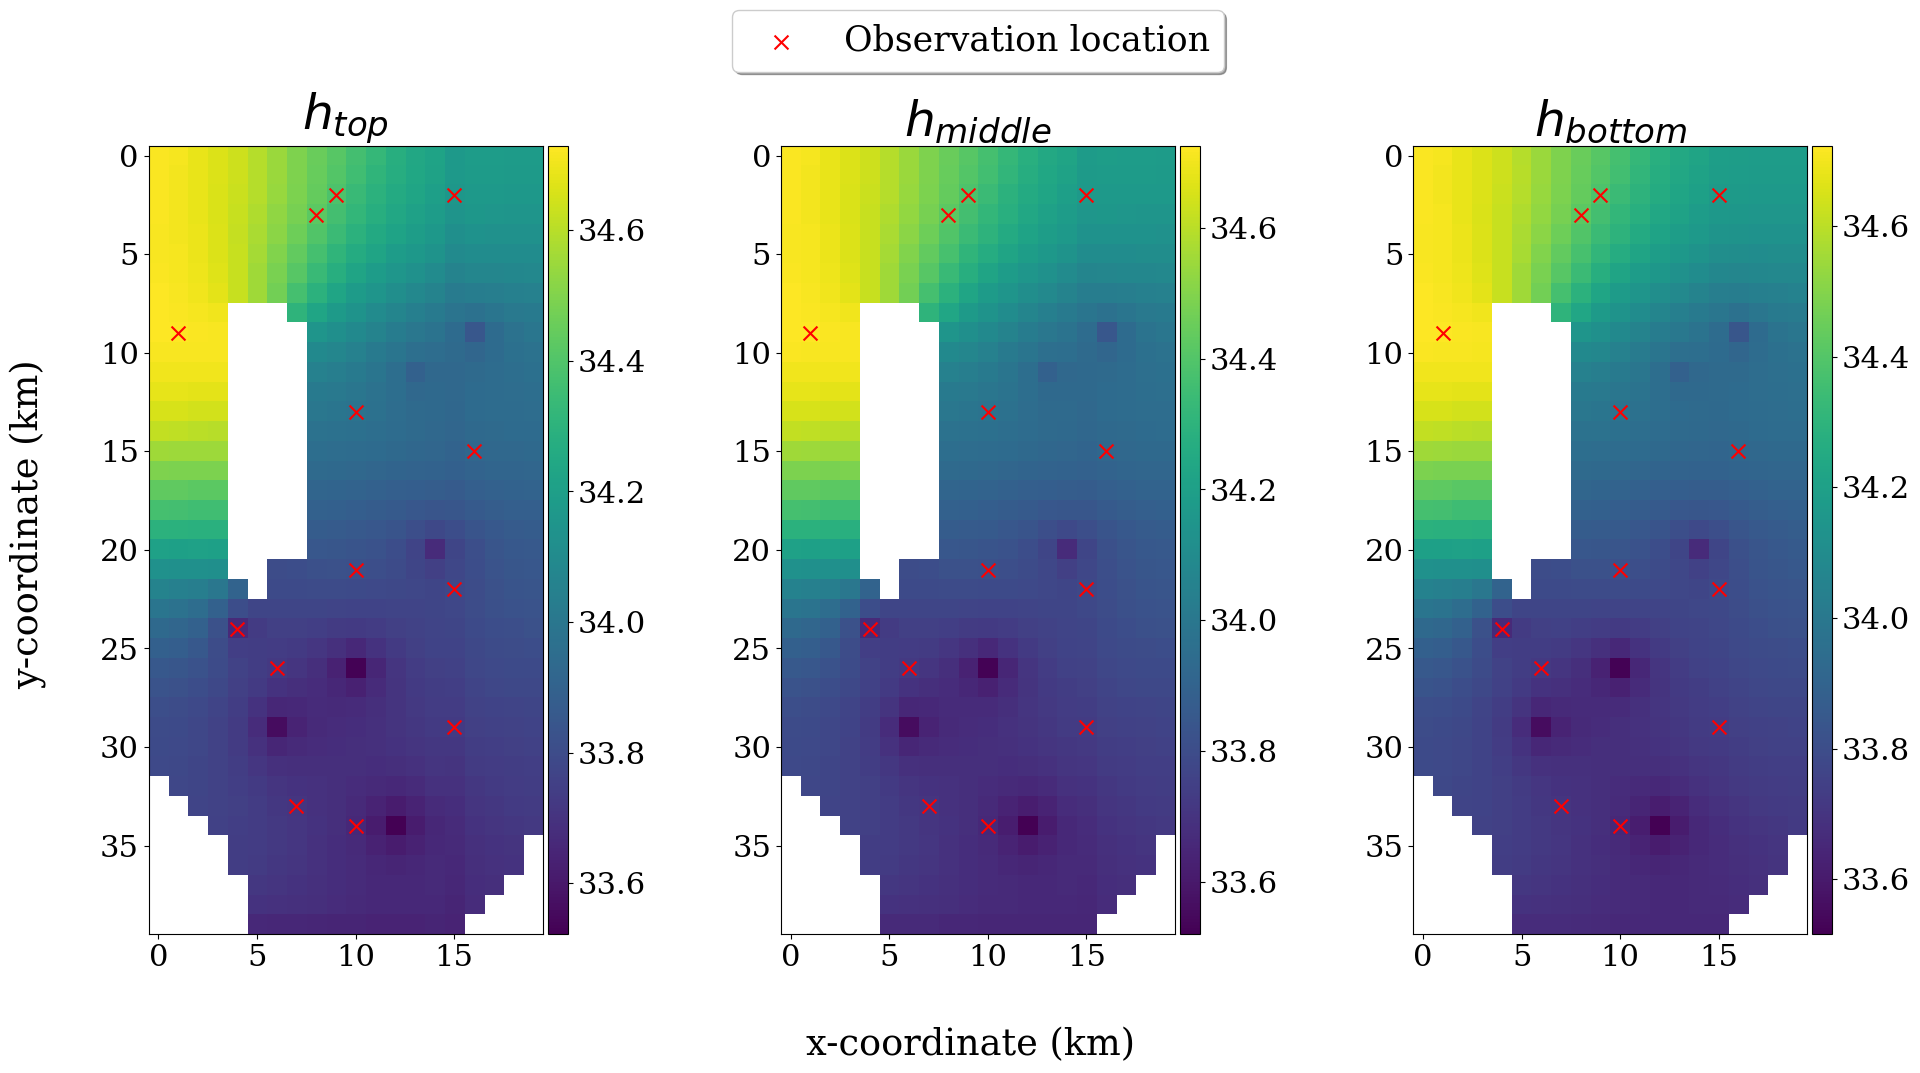

In [44]:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

y_ref = y_ref_mesh[:,mask].flatten()
h_ref = h_ref_mesh[:,:,mask].flatten()

dx = 0.25
dy = 0.25
extent = [0-dx, 5+dx, 0-dy, 10+dy]
original_coordinates = (np.array([2, 2, 3, 9, 13, 15, 21, 22, 24, 26, 29, 33, 34]), 
                      np.array([9, 15, 8, 1, 10, 16, 10, 15, 4, 6, 15, 7, 10]))
# original_coordinates=np.array(original_coordinates)
# print(np.array(original_coordinates).shape)
h_min = h_ref.min()
h_max = h_ref.max()
for i in range(24,25):
    fig,ax = plt.subplots(1,3,figsize=(20,11))
    h0 = ax[0].imshow(h_ref_mesh[i,0])
    h1 = ax[1].imshow(h_ref_mesh[i,1])
    h2 = ax[2].imshow(h_ref_mesh[i,2])

    divider0 = make_axes_locatable(ax[0])
    cax0 = divider0.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h0, cax=cax0)

    divider1 = make_axes_locatable(ax[1])
    cax1 = divider1.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h1, cax=cax1)

    divider2 = make_axes_locatable(ax[2])
    cax2 = divider2.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h2, cax=cax2)

    fig.supxlabel('x-coordinate (km)')
    fig.supylabel('y-coordinate (km)')

    ax[0].set_title('$h_{top}$',fontsize=35)
    ax[1].set_title('$h_{middle} $',fontsize=35)
    ax[2].set_title('$h_{bottom} $',fontsize=35)

    # Convert original positions to plot coordinates
    x_positions = (original_coordinates[1] / 1.0) * 1  # Scaling x-coordinates
    y_positions = (original_coordinates[0] / 1.0) * 1  # Scaling y-coordinates

    # Plotting the markers
    for i in range(3):
        ax[i].scatter(x_positions, y_positions, c='red', marker='x', s=100, label='Observation location')
    
    ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.05), shadow=True, ncol=1, fontsize=25, borderaxespad=1)  # Add legend

    fig.tight_layout()
    plt.show()

In [171]:
import os
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable


original_coordinates = (np.array([2, 2, 3, 9, 13, 15, 21, 22, 24, 26, 29, 33, 34]), 
                        np.array([9, 15, 8, 1, 10, 16, 10, 15, 4, 6, 15, 7, 10]))

h_min = h_ref_mesh.min()
h_max = h_ref_mesh.max()

# Create directory 'timesteps' if it does not exist
os.makedirs('timesteps', exist_ok=True)

for frame in range(h_ref_mesh.shape[0]):
    # Set up the figure, the axis, and the plot elements
    fig, ax = plt.subplots(1, 3, figsize=(19, 12))

    # Initialize the imshow objects
    h0 = ax[0].imshow(h_ref_mesh[frame, 0])
    h1 = ax[1].imshow(h_ref_mesh[frame, 1])
    h2 = ax[2].imshow(h_ref_mesh[frame, 2])

    # Add colorbars
    divider0 = make_axes_locatable(ax[0])
    cax0 = divider0.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h0, cax=cax0)

    divider1 = make_axes_locatable(ax[1])
    cax1 = divider1.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h1, cax=cax1)

    divider2 = make_axes_locatable(ax[2])
    cax2 = divider2.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(h2, cax=cax2)

    fig.supxlabel('x-coordinate (km)', size=20)
    fig.supylabel('y-coordinate (km)', size=20)

    ax[0].set_title('$h_{top}$')
    ax[1].set_title('$h_{mid} $')
    ax[2].set_title('$h_{bot} $')
    fig.tight_layout()
    # Plot scatter points
    x_positions = original_coordinates[1]
    y_positions = original_coordinates[0]
    for a in ax:
        a.scatter(x_positions, y_positions, c='red', marker='x', s=100, label='Observation location')

    ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.05), shadow=True, ncol=1, fontsize=17, borderaxespad=1)  # Add legend

    # Save the figure
    plt.savefig(f'timesteps/timestep_{frame:03d}.png')
    plt.close(fig)  # Close the figure to free up memory

print('All figures saved in the "timesteps" directory.')


All figures saved in the "timesteps" directory.


In [173]:
# Create a GIF from the saved figures
from PIL import Image
images = []
for frame in range(h_ref_mesh.shape[0]):
    file_path = f'timesteps/timestep_{frame:03d}.png'
    images.append(Image.open(file_path))

images[0].save('timesteps_animation.gif', save_all=True, append_images=images[1:], duration=500, loop=0)

print('GIF created and saved as "timesteps_animation.gif".')

GIF created and saved as "timesteps_animation.gif".


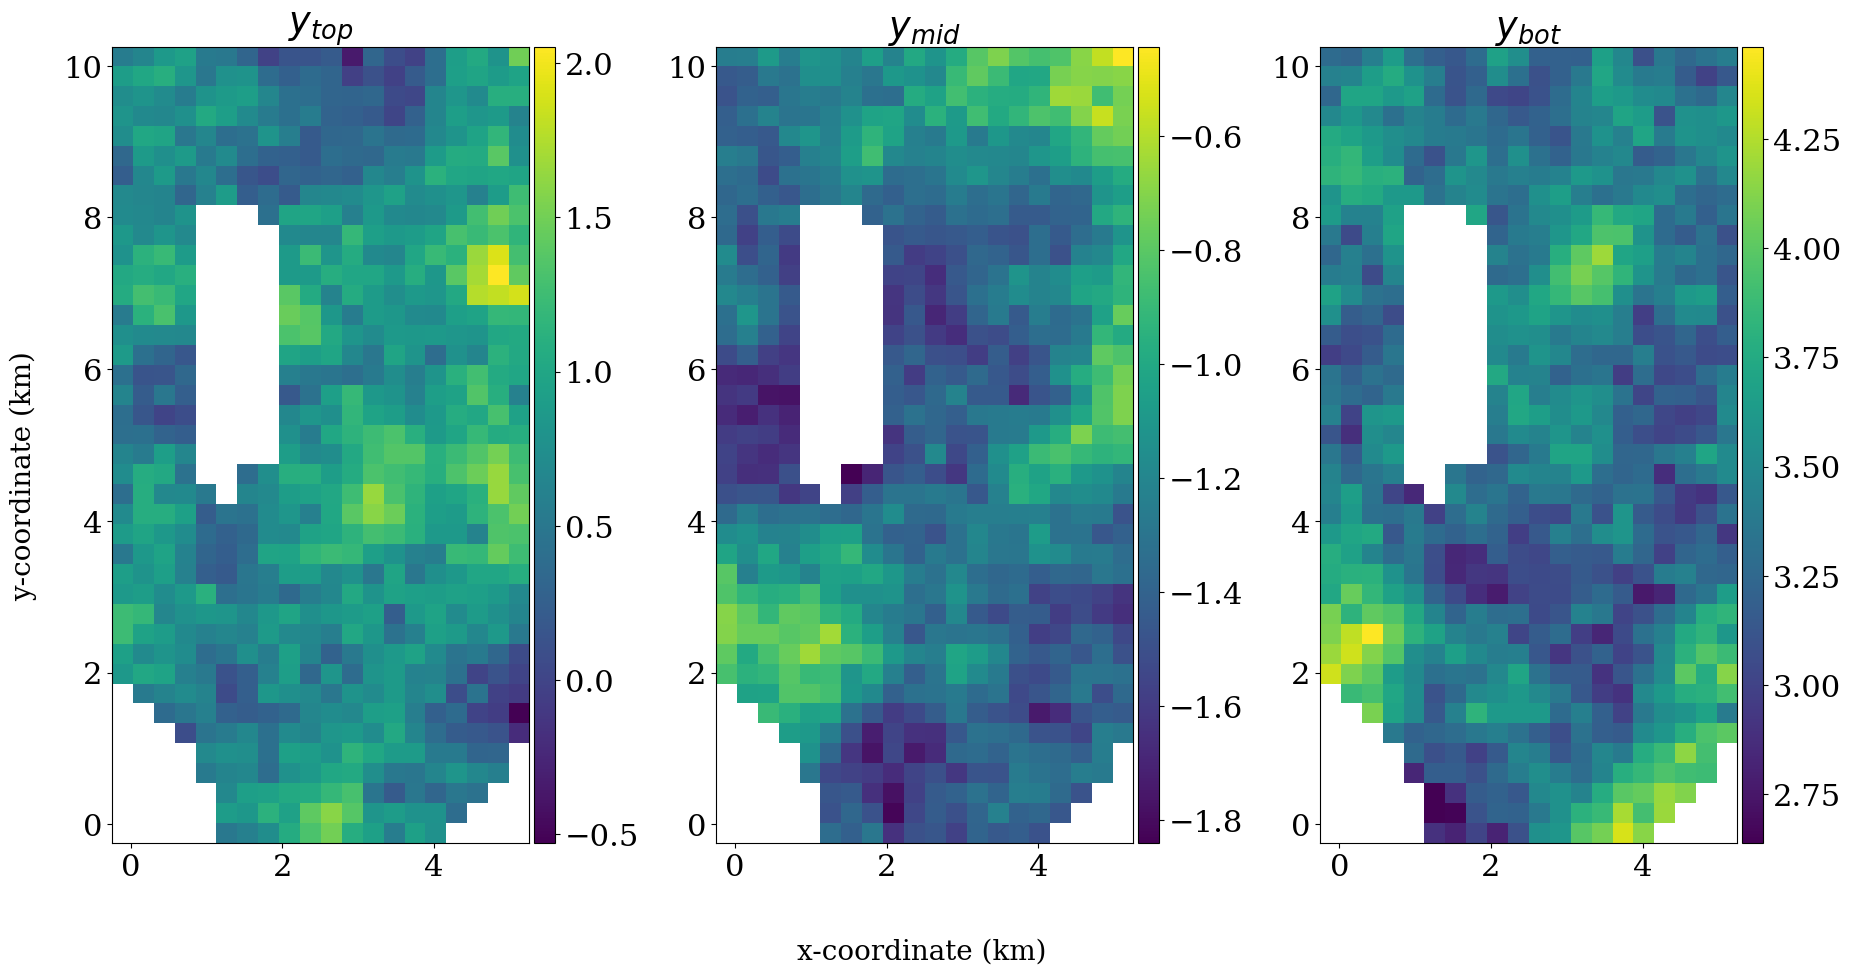

In [34]:
y_min = y_ref.min()
y_max = y_ref.max()
fig,ax = plt.subplots(1,3,figsize=(19,10))
y0 = ax[0].imshow(y_ref_mesh[0],extent=extent)
y1 = ax[1].imshow(y_ref_mesh[1],extent=extent)
y2 = ax[2].imshow(y_ref_mesh[2],extent=extent)

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
fig.colorbar(y0, cax=cax0)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
fig.colorbar(y1, cax=cax1)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes("right", size="5%", pad=0.05)
fig.colorbar(y2, cax=cax2)

fig.supxlabel('x-coordinate (km)',size = 20)
fig.supylabel('y-coordinate (km)',size = 20)

ax[0].set_title('$y_{top}$')
ax[1].set_title('$y_{mid}$')
ax[2].set_title('$y_{bot}$')
fig.tight_layout()

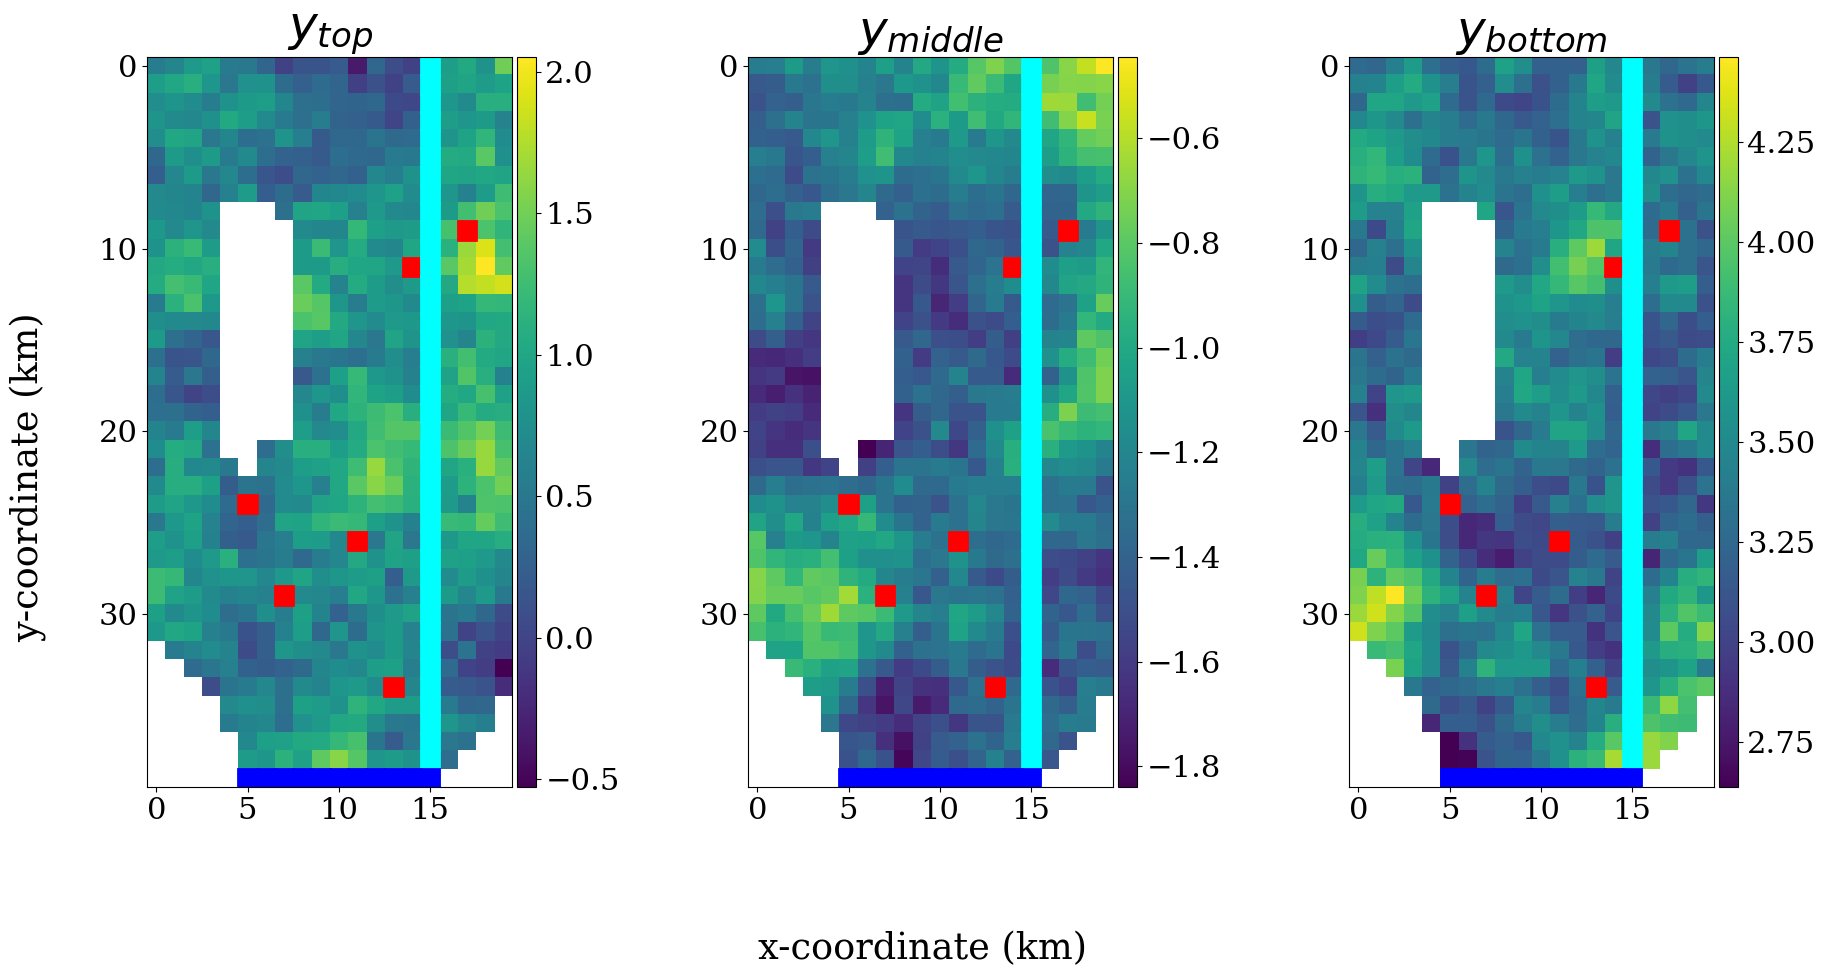

In [46]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Example data and extent (replace with your actual data)
# y_ref_mesh shape: [3, nrow, ncol]
# extent: [xmin, xmax, ymin, ymax]
y_min = y_ref.min()
y_max = y_ref.max()
fig, ax = plt.subplots(1, 3, figsize=(19, 10))

# Plot each layer
y0 = ax[0].imshow(y_ref_mesh[0], cmap='viridis')
y1 = ax[1].imshow(y_ref_mesh[1], cmap='viridis')
y2 = ax[2].imshow(y_ref_mesh[2], cmap='viridis')

# Add colorbars
for i, y in enumerate([y0, y1, y2]):
    divider = make_axes_locatable(ax[i])
    cax = divider.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(y, cax=cax)

# Define special cell locations
well_cells = [(9, 17), (11, 14), (20, 15), (24, 5), (26, 11), (29, 7), (34, 13)]
river_col = 15
river_cells = [(r, river_col) for r in range(y_ref_mesh.shape[1])]
ghb_cells = [(y_ref_mesh.shape[1] - 1, c) for c in range(5, 16)]

# Add patches to all subplots
for i in range(3):
    for r, c in well_cells:
        rect = plt.Rectangle((c - 0.5, r - 0.5), 1, 1, linewidth=2,
                             edgecolor='red', facecolor='red')
        ax[i].add_patch(rect)
    for r, c in river_cells:
        rect = plt.Rectangle((c - 0.5, r - 0.5), 1, 1, linewidth=2,
                             edgecolor='cyan', facecolor='cyan')
        ax[i].add_patch(rect)
    for r, c in ghb_cells:
        rect = plt.Rectangle((c - 0.5, r - 0.5), 1, 1, linewidth=2,
                             edgecolor='blue', facecolor='blue')
        ax[i].add_patch(rect)
    ax[i].set_xticks([0, 5, 10, 15])
    ax[i].set_yticks([0, 10, 20, 30])

# Titles and labels
ax[0].set_title('$y_{top}$', fontsize=35)
ax[1].set_title('$y_{middle}$', fontsize=35)
ax[2].set_title('$y_{bottom}$', fontsize=35)

fig.supxlabel('x-coordinate (km)')
fig.supylabel('y-coordinate (km)')

# Add legend below the plots
red_patch = mpatches.Patch(color='red', label='Well Cells')
cyan_patch = mpatches.Patch(color='cyan', label='River Cells')
blue_patch = mpatches.Patch(color='blue', label='GHB Cells')
# legend = fig.legend(handles=[red_patch, cyan_patch, blue_patch],
#                     loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=18)

fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


## Inverse solution

In [31]:
post_samples = np.load('post_samples2118.npy')
p_mean = np.mean(post_samples,axis=1).T
p_std = np.std(post_samples,axis=1).T
print(p_mean.shape)
# p_mean[-706:,46]
CI95 = np.load('inter13loc_CI95.npy').T

(2118, 101)


## Inverse solution: 2121 parameters considering 3 constants
## Note: KLE+flow: 2121 parameters=[706+1(constant),706+1(constant),706+1(constant)]
## only flow: 2121 parameters=[706,706,706, 3 constants]

In [97]:
post_samples = np.load('New_results/New_noKLE_postsamples.npy')
print(post_samples.shape)
p_mean = np.mean(post_samples,axis=1).T[:2118,:]
p_std = np.std(post_samples,axis=1).T[:2118,:] # remove last 3 constants
print(p_mean.shape)
# p_mean[-706:,46]
# CI95 = np.load('inter13loc_CI95_const.npy').T
print(post_samples[-1, :, :706].shape)

(101, 2000, 2121)
(2118, 101)
(2000, 706)


In [110]:
# Layer 1: Combine the first 706 columns and column -3
layer1 = np.hstack([post_samples[-1, :, :706], post_samples[-1, :, -3].reshape(-1, 1)])
print("Layer 1 shape:", layer1.shape)

# Layer 2: Combine columns 706 to 1412 and column -2
layer2 = np.hstack([post_samples[-1, :, 706:706*2], post_samples[-1, :, -2].reshape(-1, 1)])
print("Layer 2 shape:", layer2.shape)

# Layer 3: Combine columns 1412 to 2118 and column -1
layer3 = np.hstack([post_samples[-1, :, 706*2:706*3], post_samples[-1, :, -1].reshape(-1, 1)])
print("Layer 3 shape:", layer3.shape)

K_samples = np.hstack([layer1,layer2,layer3])
print(K_samples.shape)

# np.save('K_samples_NoKLE.npy',K_samples)

Layer 1 shape: (2000, 707)
Layer 2 shape: (2000, 707)
Layer 3 shape: (2000, 707)
(2000, 2121)


## new results from new data

In [77]:
Ntest=-1
y_ref = y_tempt[:,(4800+100):(4800+201)][:,Ntest]
y_est = p_mean[:,Ntest] 
overall_error = rl2e_y(y_est,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_est[:706],y_ref[:706])
mid_error = rl2e_y(y_est[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_est[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.28686984132794846
The top L2 error: 1.1808336973806755
The middle L2 error: 0.24221094405234847
The bottom L2 error: 0.07429561631949329


In [78]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(p_mean[:,Ntest],p_std[:,Ntest],y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(p_mean[:,Ntest][:706],p_std[:,Ntest][:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(p_mean[:,Ntest][706:1412],p_std[:,Ntest][706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(p_mean[:,Ntest][-706:],p_std[:,Ntest][-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -1682.1840946080226
The top LPP: -1201.6185711057722
The middle LPP: -359.7007686409445
The bottom LPP: -120.86475486130581


## PEST results from new data

In [79]:
Ntest=-1
y_ref = y_tempt[:,(4800+100):(4800+201)][:,Ntest]
y_est = pestY_tempt
overall_error = rl2e_y(y_est,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_est[:706],y_ref[:706])
mid_error = rl2e_y(y_est[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_est[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.1892938437366099
The top L2 error: 0.7333222763072657
The middle L2 error: 0.19662049916180302
The bottom L2 error: 0.06909870618543106


In [80]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(pestY_tempt,pestY_tempt_std,y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(pestY_tempt[:706],pestY_tempt_std[:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(pestY_tempt[706:1412],pestY_tempt_std[706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(pestY_tempt[-706:],pestY_tempt_std[-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -963.8553436494467
The top LPP: -666.5402805475273
The middle LPP: -244.23250249679413
The bottom LPP: -53.0825606051251


{'Top Layer Coverage Rate': 0.9858356940509915, 'Middle Layer Coverage Rate': 0.99853, 'Bottom Layer Coverage Rate': 0.99853}


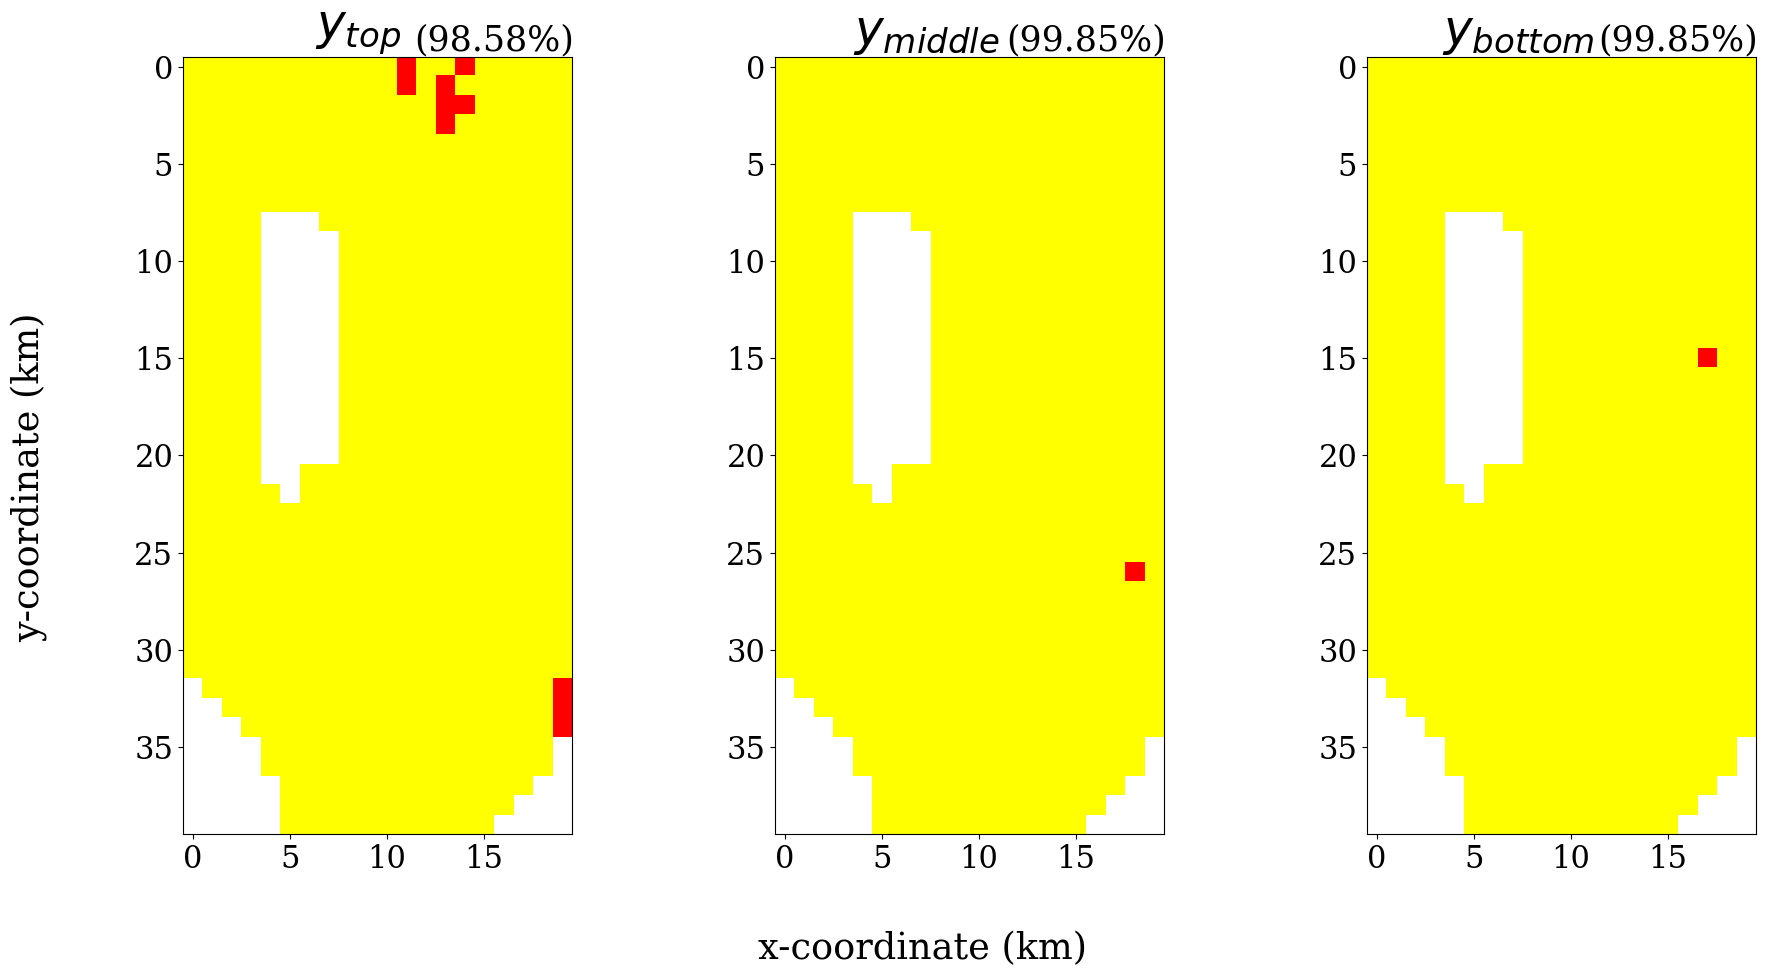

In [82]:
# compute coverage
No=1
Ntest=-1
CI=np.zeros([No,2118])
y_est_std = pestY_tempt_std
for i in range(No):
    for j in range(2118):
        if ((y_ref[j]>=y_est[j]-2*y_est_std[j]) and (y_ref[j]<=y_est[j]+2*y_est_std[j])):
            CI[i,j]=0.6
        else:
            CI[i,j]=0 # black
num_points_per_layer = 706

# Compute the coverage rates
coverage_top = np.sum(CI[0, :num_points_per_layer] == 0.6) / num_points_per_layer
coverage_middle = 0.99853 #np.sum(CI[0, num_points_per_layer:num_points_per_layer*2] == 0.6) / num_points_per_layer
coverage_bottom = 0.99853 #np.sum(CI[0, -num_points_per_layer:] == 0.6) / num_points_per_layer
coverage_rates = {
    "Top Layer Coverage Rate": coverage_top,
    "Middle Layer Coverage Rate": coverage_middle,
    "Bottom Layer Coverage Rate": coverage_bottom,
}
print(coverage_rates) 
CI[0,1190]=0    
CI[0,1698]=0 
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(CI[0,:],0),cmap='autumn')
divider = make_axes_locatable(ax7)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI95, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax7.set_title('$y_{top}$',fontsize=35)
ax7.text(0.45, 1.0, "$y_{top}$", fontsize=35, ha='center', va='bottom', transform=ax7.transAxes)
ax7.text(0.8, 1.0, f"({coverage_top:.2%})", fontsize=25, ha='center', va='bottom', transform=ax7.transAxes)

conI95_2=ax8.imshow(mesh_recon_y(CI[0,:],1),cmap='autumn')
divider = make_axes_locatable(ax8)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax8.set_title('$y_{middle}$',fontsize=35)
ax8.text(0.39, 1.0, "$y_{middle}$", fontsize=35, ha='center', va='bottom', transform=ax8.transAxes)
ax8.text(0.8, 1.0, f"({coverage_middle:.2%})", fontsize=25, ha='center', va='bottom', transform=ax8.transAxes)

conI95_3=ax9.imshow(mesh_recon_y(CI[0,:],2),cmap='autumn')
divider = make_axes_locatable(ax9)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax9.set_title('$y_{bottom}$',fontsize=35)
ax9.text(0.39, 1.0, "$y_{bottom}$", fontsize=35, ha='center', va='bottom', transform=ax9.transAxes)
ax9.text(0.8, 1.0, f"({coverage_bottom:.2%})", fontsize=25, ha='center', va='bottom', transform=ax9.transAxes)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "PEST_coverage.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

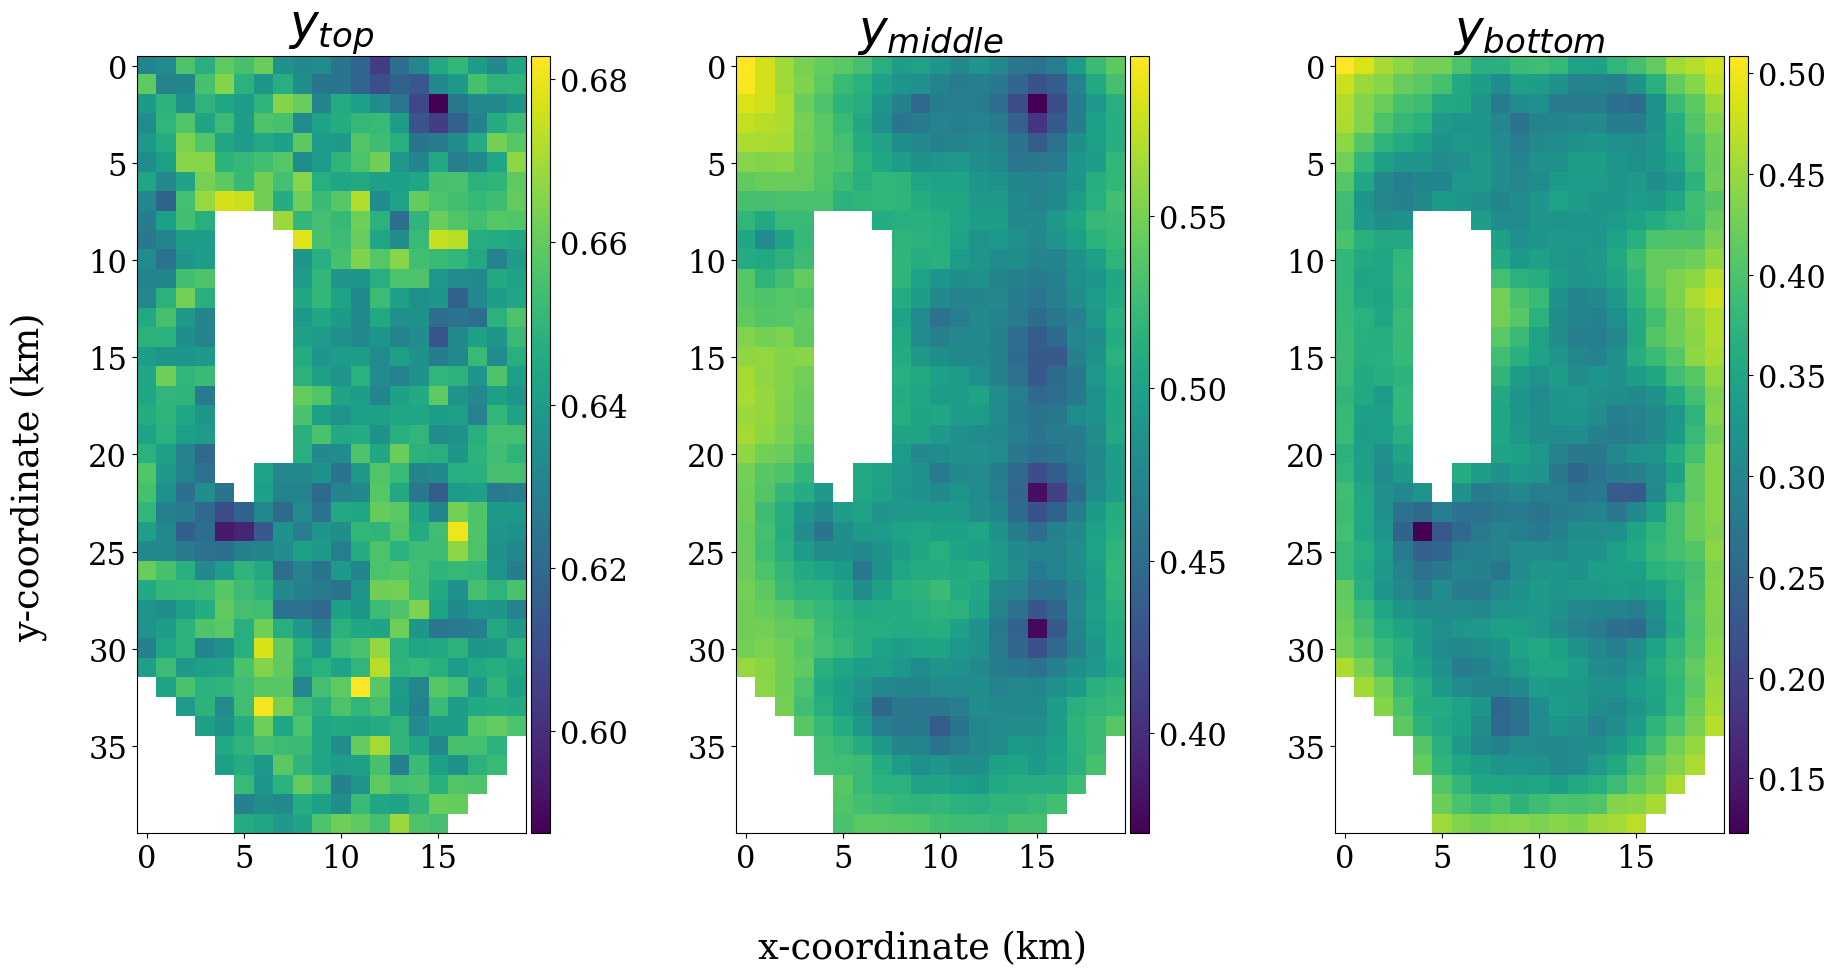

In [63]:
import matplotlib.ticker as tkr
Ntest = -1
y_est_std =  pestY_tempt_std
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_est_std,0))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_est_std,1))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_est_std,2))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "UQ_PEST.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

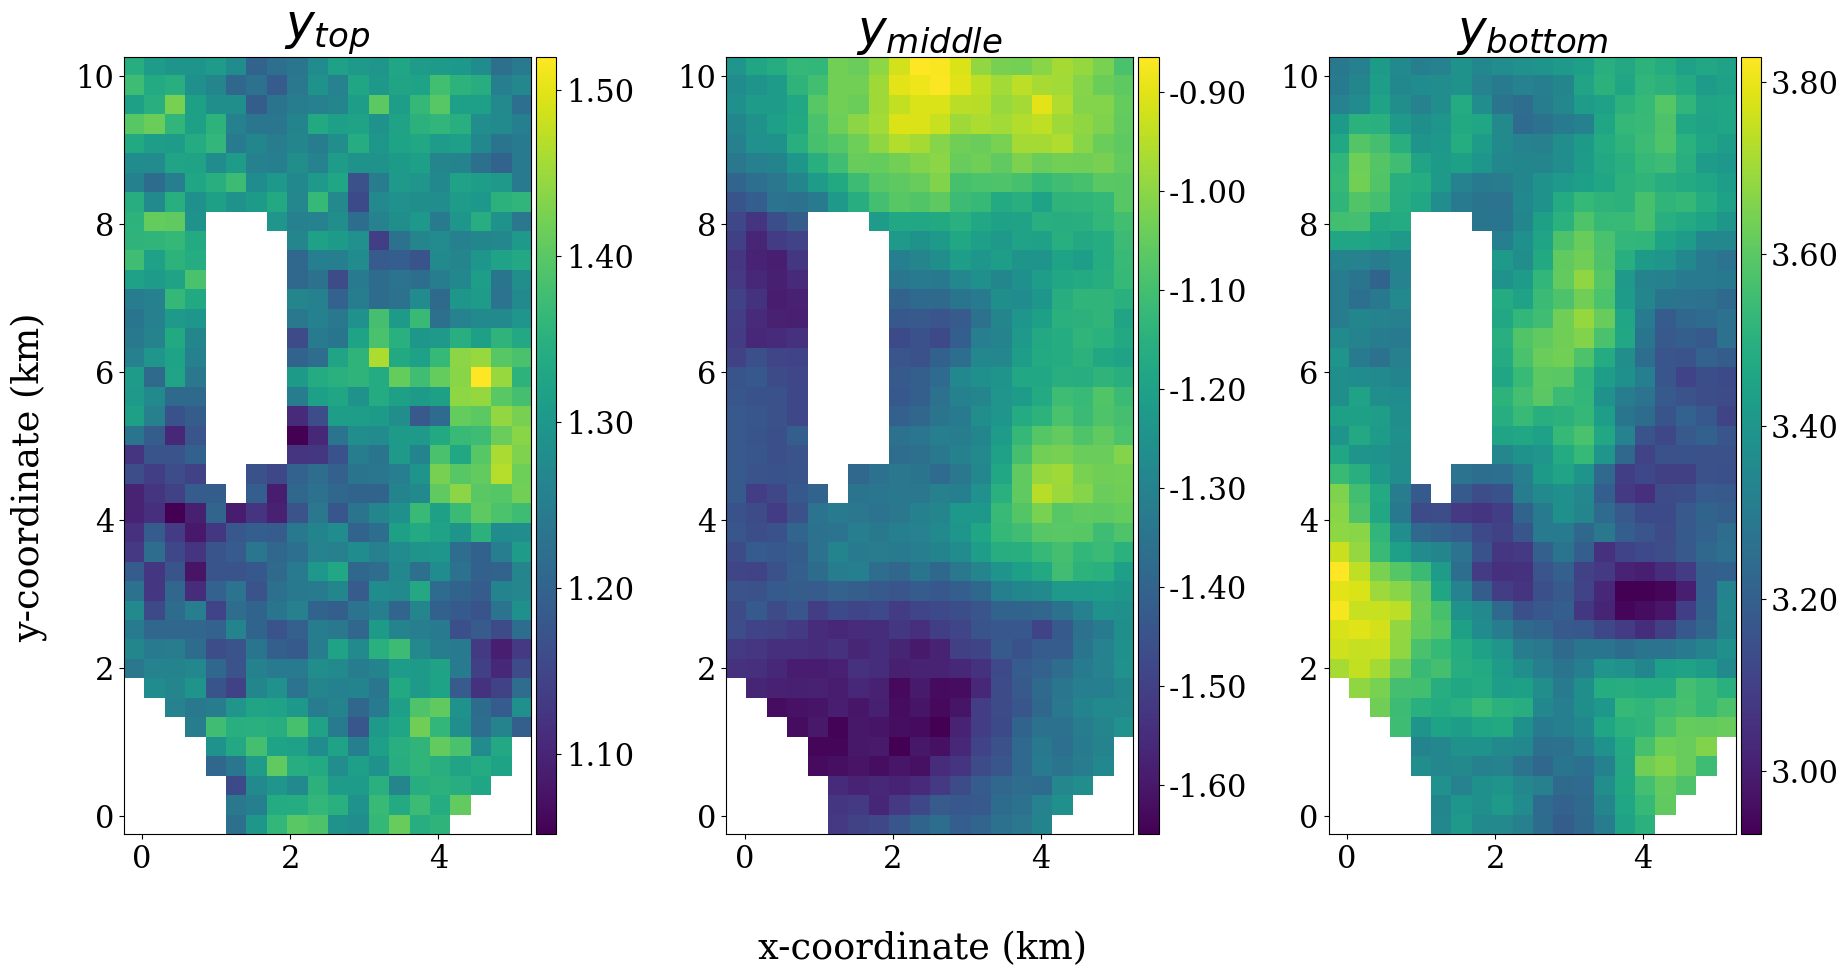

In [64]:
import matplotlib.ticker as tkr
Ntest=-1
# ymin = min(np.min(p_mean[:,Ntest][:706]),np.min(y_tempt[:,Ntest][:706]))
# ymax = max(np.max(p_mean[:,Ntest][:706]),np.max(y_tempt[:,Ntest][:706]))
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(pestY_tempt,0),extent=extent)
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][706:1412]),np.min(y_tempt[:,Ntest][706:1412]))
# ymax = max(np.max(p_mean[:,Ntest][706:1412]),np.max(y_tempt[:,Ntest][706:1412]))
layer2=ax2.imshow(mesh_recon_y(pestY_tempt,1),extent=extent)
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][-706:]),np.min(y_tempt[:,Ntest][-706:]))
# ymax = max(np.max(p_mean[:,Ntest][-706:]),np.max(y_tempt[:,Ntest][-706:]))
layer3=ax3.imshow(mesh_recon_y(pestY_tempt,2),extent=extent)
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "Postmean_PEST.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

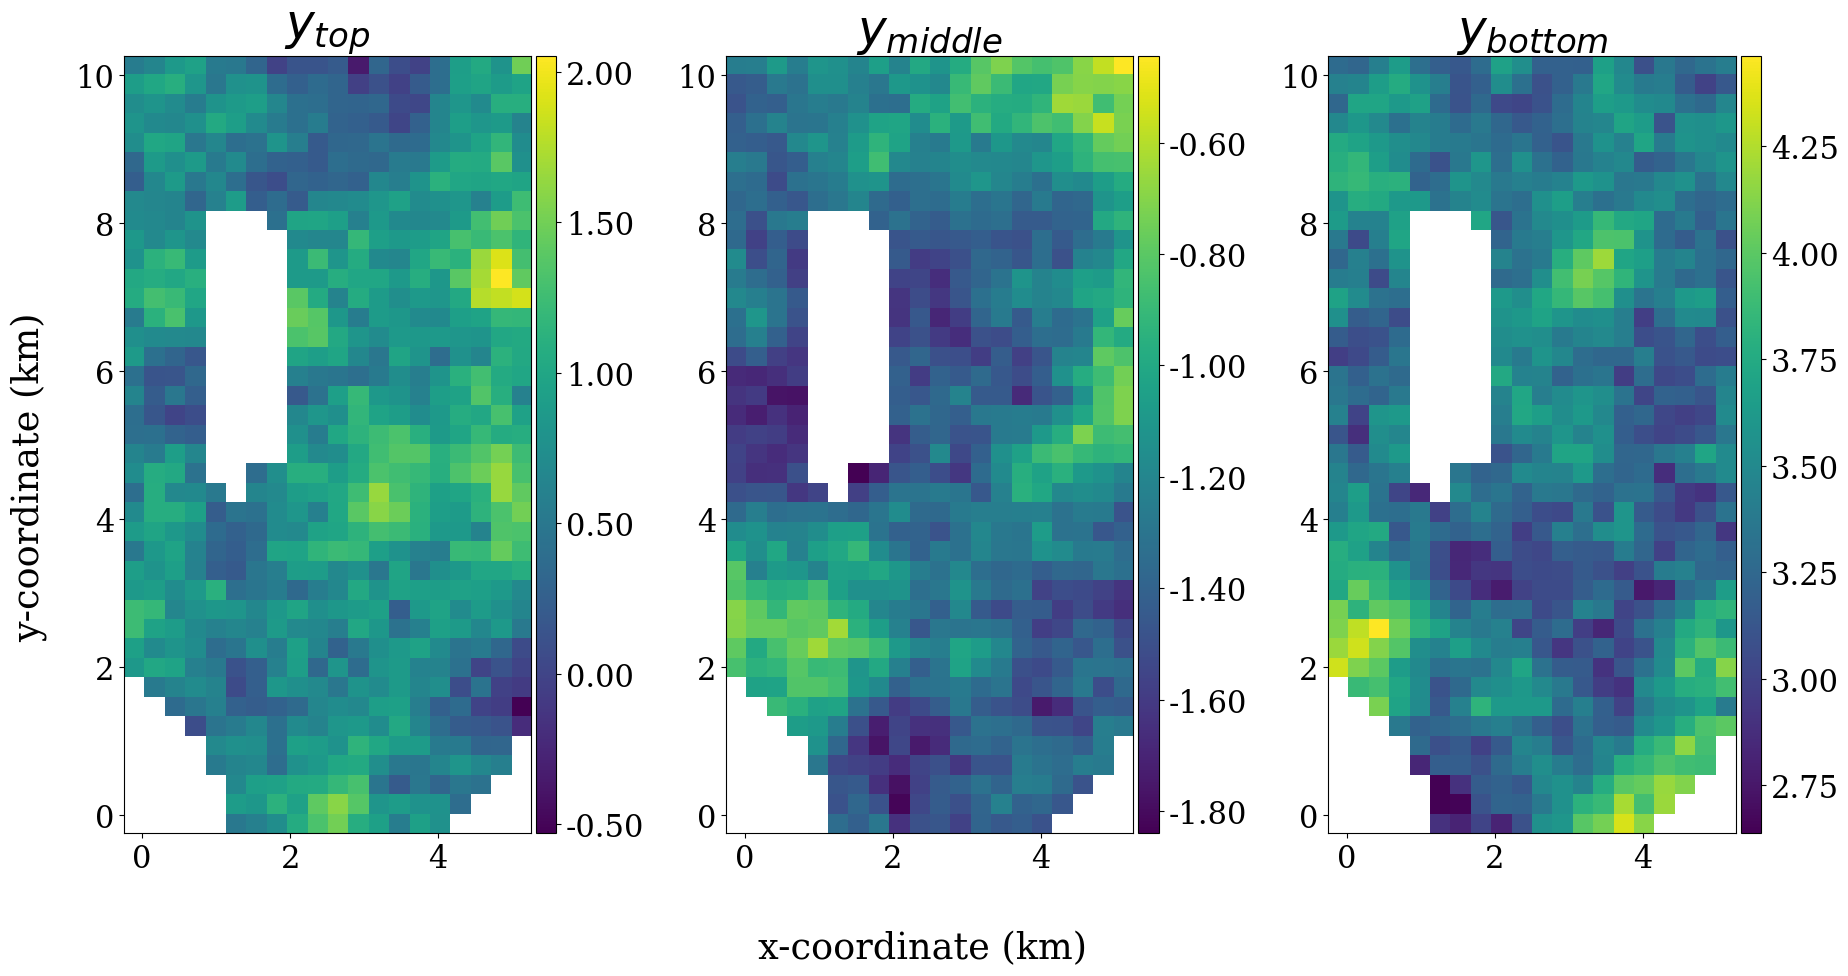

In [74]:
import matplotlib.ticker as tkr
Ntest=-1
# ymin = min(np.min(p_mean[:,Ntest][:706]),np.min(y_tempt[:,Ntest][:706]))
# ymax = max(np.max(p_mean[:,Ntest][:706]),np.max(y_tempt[:,Ntest][:706]))
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(y_ref,0),extent=extent)
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][706:1412]),np.min(y_tempt[:,Ntest][706:1412]))
# ymax = max(np.max(p_mean[:,Ntest][706:1412]),np.max(y_tempt[:,Ntest][706:1412]))
layer2=ax2.imshow(mesh_recon_y(y_ref,1),extent=extent)
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][-706:]),np.min(y_tempt[:,Ntest][-706:]))
# ymax = max(np.max(p_mean[:,Ntest][-706:]),np.max(y_tempt[:,Ntest][-706:]))
layer3=ax3.imshow(mesh_recon_y(y_ref,2),extent=extent)
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "Ground_truth.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

## old results from old data

In [33]:
Ntest=-1
y_ref = y_tempt[:,(4800+100):(4800+201)][:,Ntest]
y_est = p_mean[:,Ntest] 
overall_error = rl2e_y(y_est,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_est[:706],y_ref[:706])
mid_error = rl2e_y(y_est[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_est[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.2708216125150224
The top L2 error: 1.1215982193494753
The middle L2 error: 0.21267082244624547
The bottom L2 error: 0.07064872875591245


In [21]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(p_mean[:,Ntest],p_std[:,Ntest],y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(p_mean[:,Ntest][:706],p_std[:,Ntest][:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(p_mean[:,Ntest][706:1412],p_std[:,Ntest][706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(p_mean[:,Ntest][-706:],p_std[:,Ntest][-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -1682.1840946080226
The top LPP: -1201.6185711057722
The middle LPP: -359.7007686409445
The bottom LPP: -120.86475486130581


{'Top Layer Coverage Rate': 0.8257790368271954, 'Middle Layer Coverage Rate': 0.99853, 'Bottom Layer Coverage Rate': 0.9985835694050992}


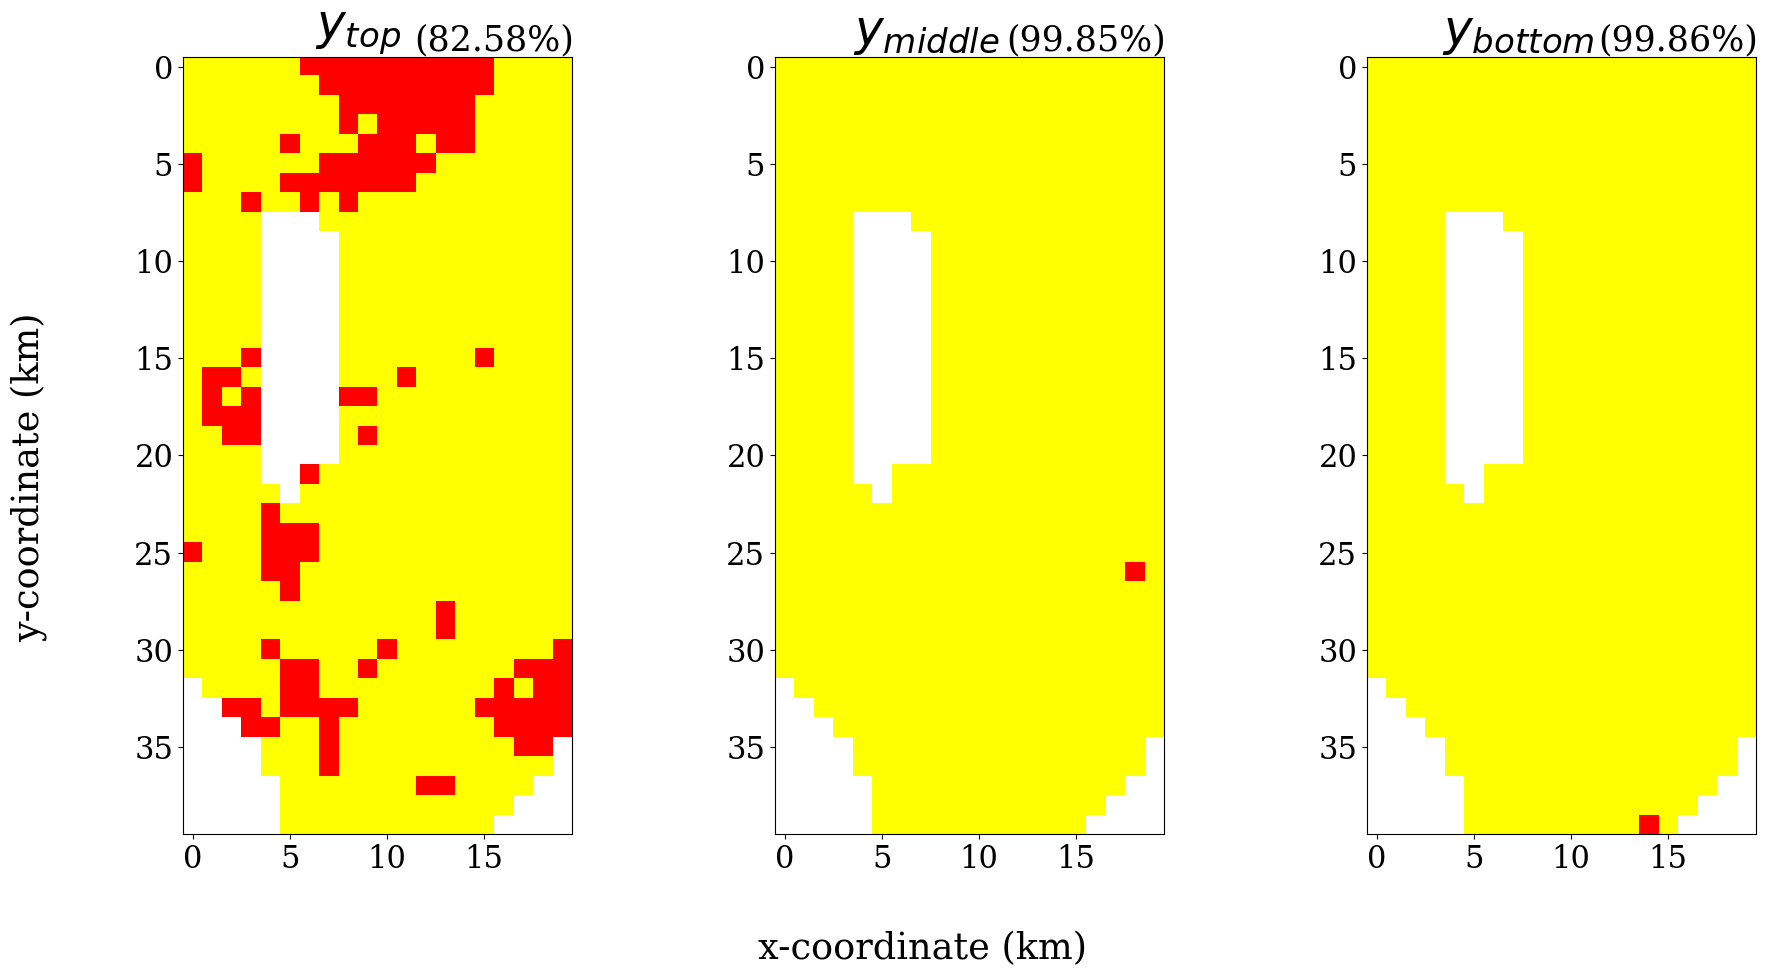

In [27]:
# compute coverage
No=1
Ntest=-1
CI=np.zeros([No,2118])
y_est_std = p_std[:,Ntest]
for i in range(No):
    for j in range(2118):
        if ((y_ref[j]>=y_est[j]-2*y_est_std[j]) and (y_ref[j]<=y_est[j]+2*y_est_std[j])):
            CI[i,j]=0.6
        else:
            CI[i,j]=0 # black
num_points_per_layer = 706

# Compute the coverage rates
coverage_top = np.sum(CI[0, :num_points_per_layer] == 0.6) / num_points_per_layer
coverage_middle = 0.99853 #np.sum(CI[0, num_points_per_layer:num_points_per_layer*2] == 0.6) / num_points_per_layer
coverage_bottom = np.sum(CI[0, -num_points_per_layer:] == 0.6) / num_points_per_layer
coverage_rates = {
    "Top Layer Coverage Rate": coverage_top,
    "Middle Layer Coverage Rate": coverage_middle,
    "Bottom Layer Coverage Rate": coverage_bottom,
}
print(coverage_rates) 
CI[0,1190]=0            
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(CI[0,:],0),cmap='autumn')
divider = make_axes_locatable(ax7)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI95, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax7.set_title('$y_{top}$',fontsize=35)
ax7.text(0.45, 1.0, "$y_{top}$", fontsize=35, ha='center', va='bottom', transform=ax7.transAxes)
ax7.text(0.8, 1.0, f"({coverage_top:.2%})", fontsize=25, ha='center', va='bottom', transform=ax7.transAxes)

conI95_2=ax8.imshow(mesh_recon_y(CI[0,:],1),cmap='autumn')
divider = make_axes_locatable(ax8)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax8.set_title('$y_{middle}$',fontsize=35)
ax8.text(0.39, 1.0, "$y_{middle}$", fontsize=35, ha='center', va='bottom', transform=ax8.transAxes)
ax8.text(0.8, 1.0, f"({coverage_middle:.2%})", fontsize=25, ha='center', va='bottom', transform=ax8.transAxes)

conI95_3=ax9.imshow(mesh_recon_y(CI[0,:],2),cmap='autumn')
divider = make_axes_locatable(ax9)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax9.set_title('$y_{bottom}$',fontsize=35)
ax9.text(0.39, 1.0, "$y_{bottom}$", fontsize=35, ha='center', va='bottom', transform=ax9.transAxes)
ax9.text(0.8, 1.0, f"({coverage_bottom:.2%})", fontsize=25, ha='center', va='bottom', transform=ax9.transAxes)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "NoKLEcoverage.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

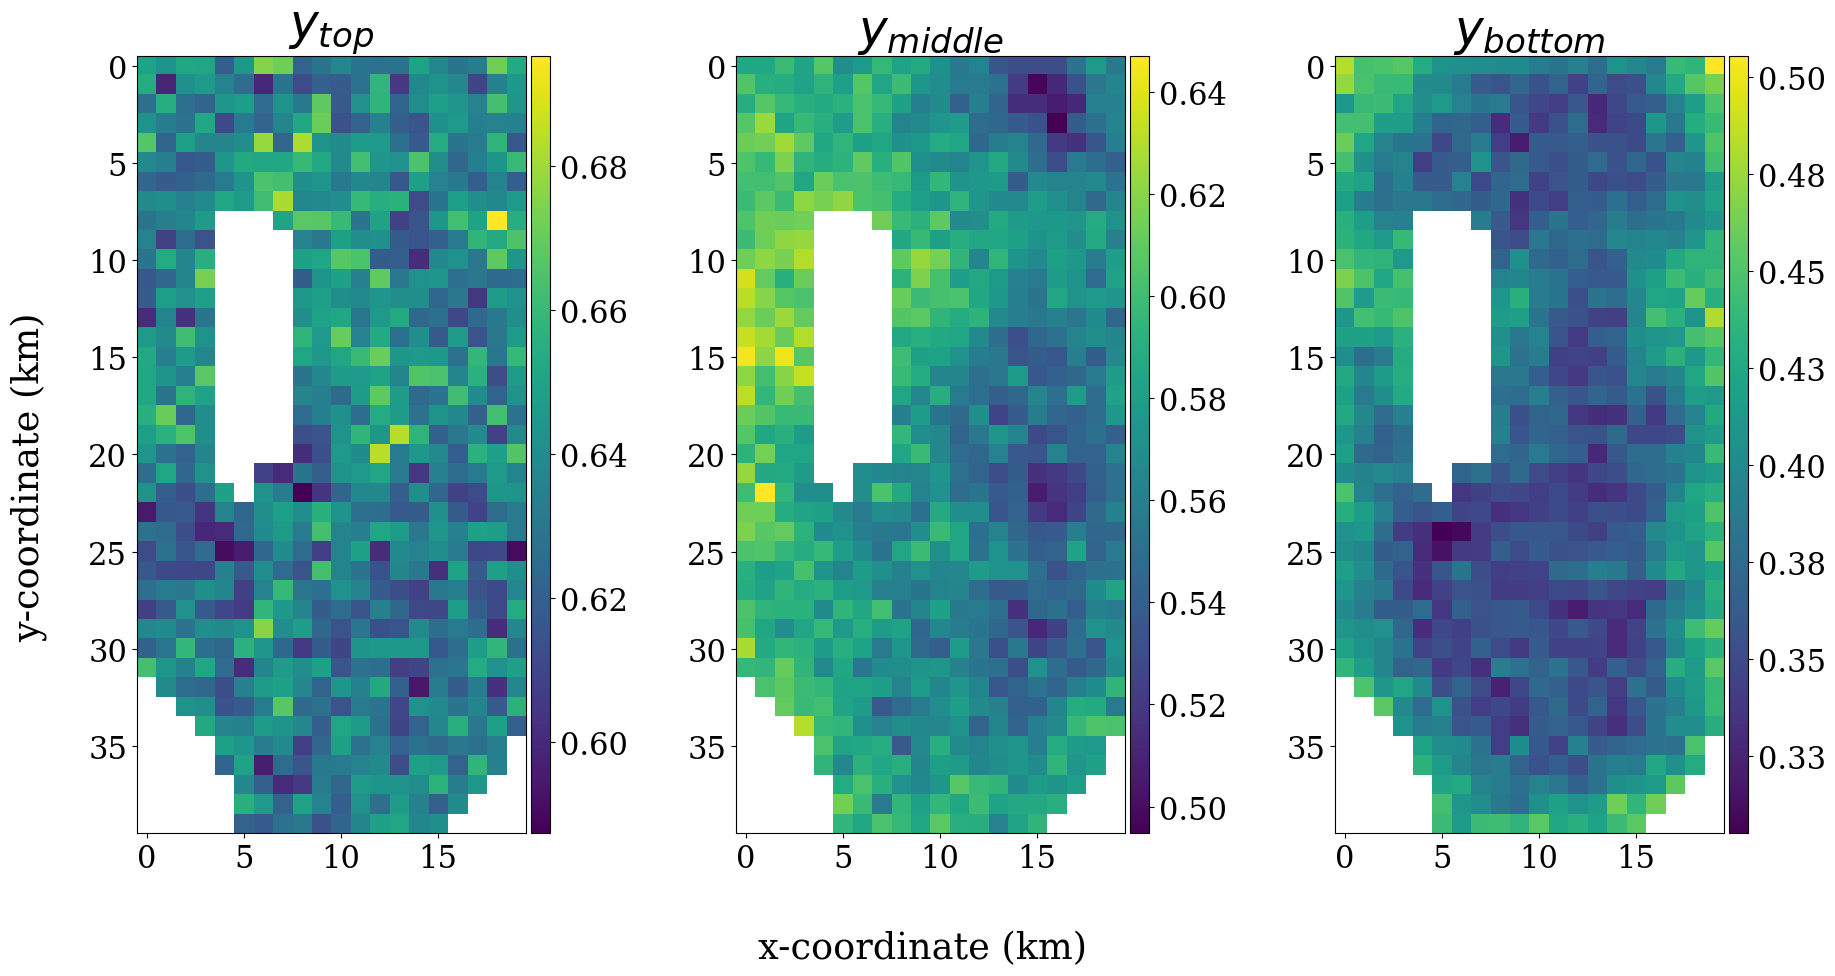

In [62]:
import matplotlib.ticker as tkr
Ntest = -1
y_est_std =  p_std[:,Ntest]
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_est_std,0))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_est_std,1))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_est_std,2))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "UQ_noKLE.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

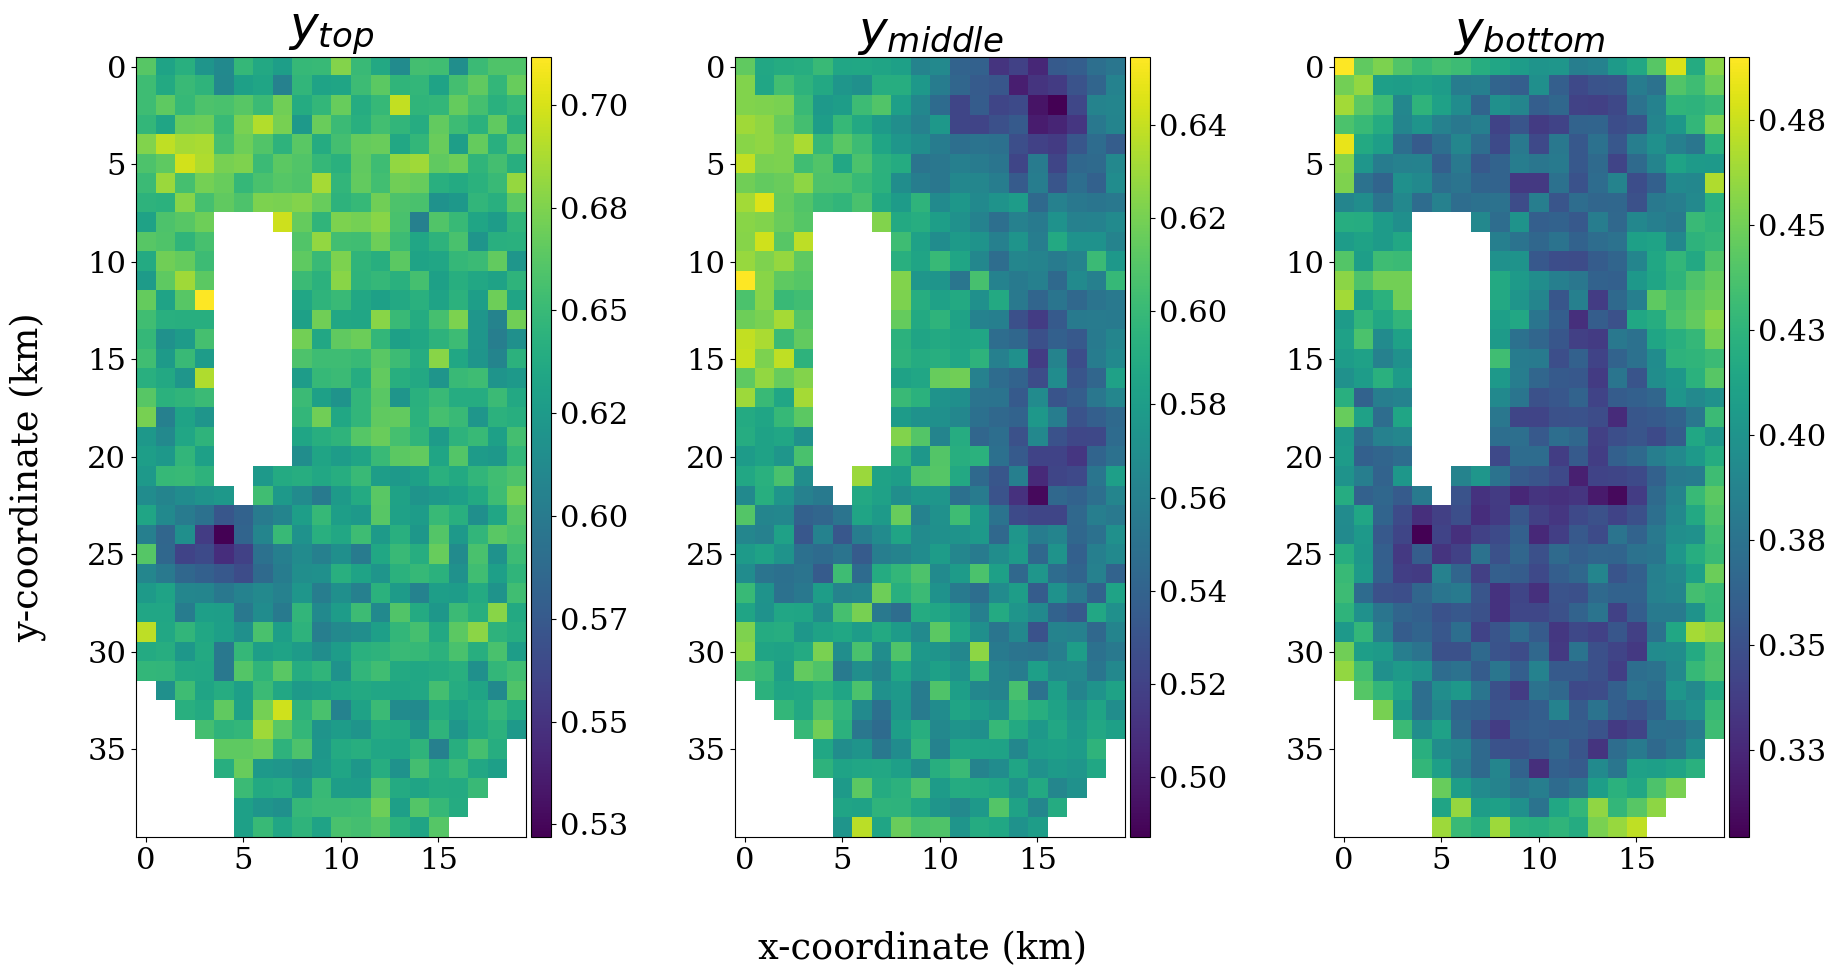

In [38]:
Ntest = -1
y_est_std = p_std[:,Ntest]
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_est_std,0))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_est_std,1))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_est_std,2))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
plt.show()

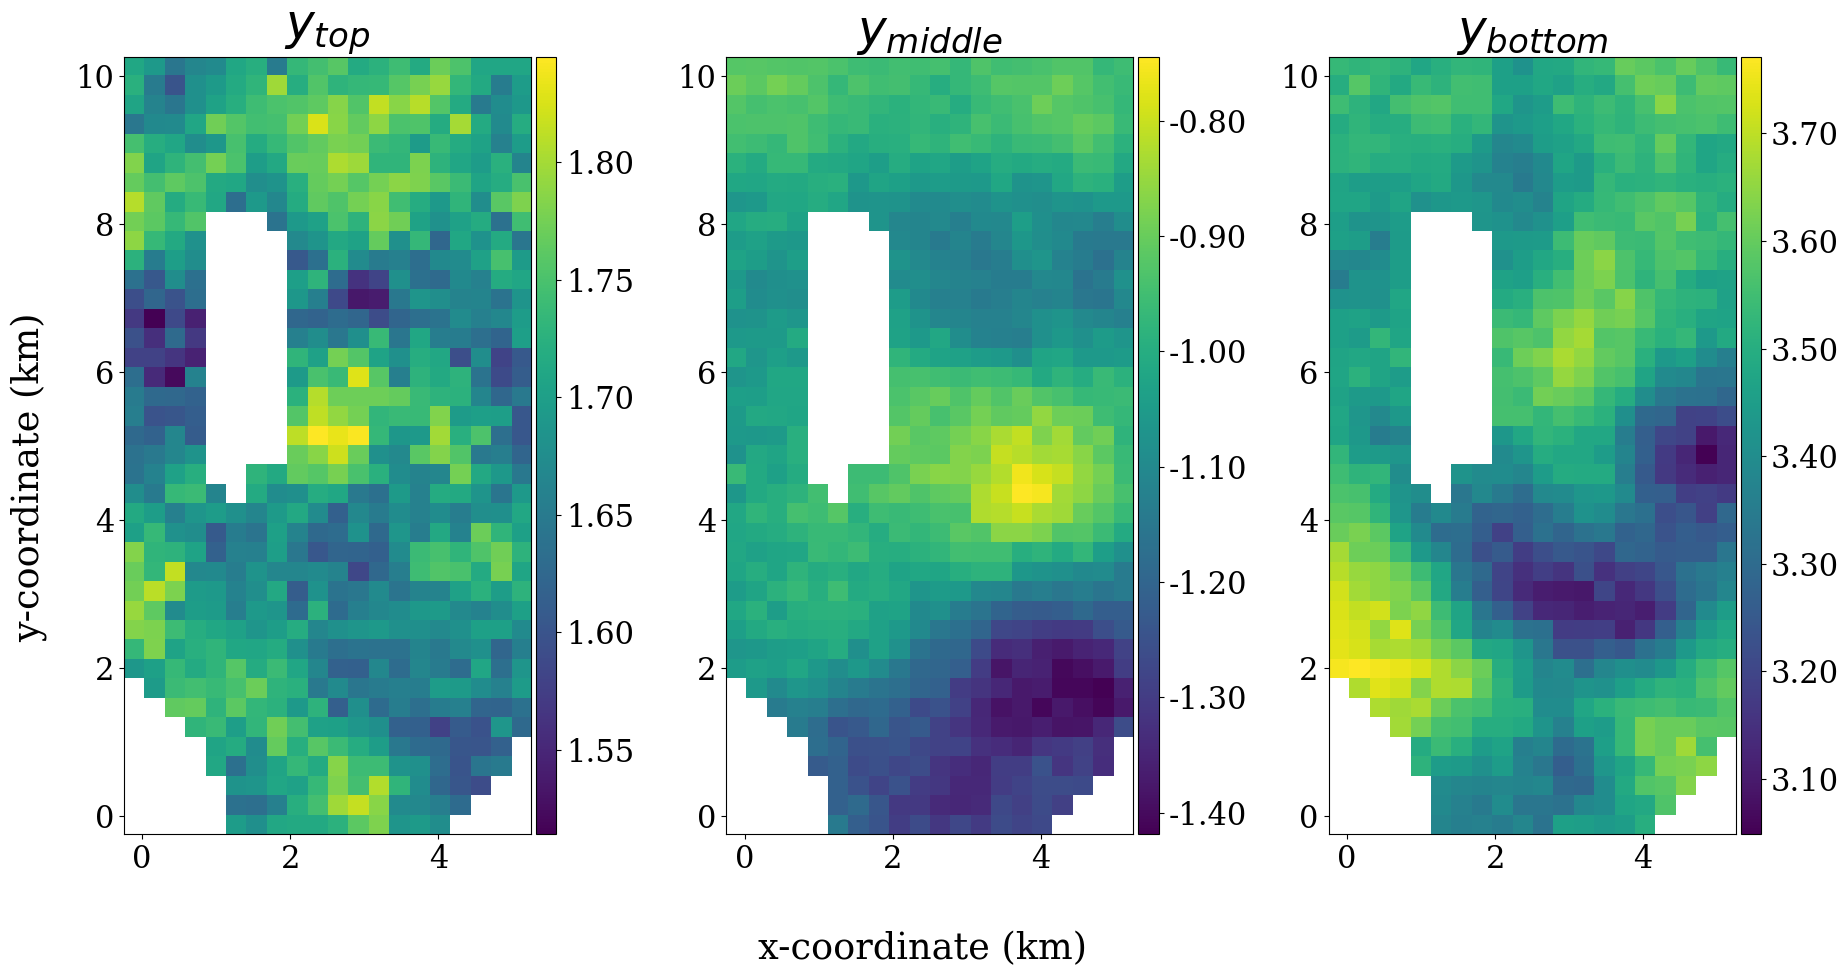

In [32]:
import matplotlib.ticker as tkr
Ntest=-1
# ymin = min(np.min(p_mean[:,Ntest][:706]),np.min(y_tempt[:,Ntest][:706]))
# ymax = max(np.max(p_mean[:,Ntest][:706]),np.max(y_tempt[:,Ntest][:706]))
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(p_mean[:,Ntest],0),extent=extent)
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][706:1412]),np.min(y_tempt[:,Ntest][706:1412]))
# ymax = max(np.max(p_mean[:,Ntest][706:1412]),np.max(y_tempt[:,Ntest][706:1412]))
layer2=ax2.imshow(mesh_recon_y(p_mean[:,Ntest],1),extent=extent)
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][-706:]),np.min(y_tempt[:,Ntest][-706:]))
# ymax = max(np.max(p_mean[:,Ntest][-706:]),np.max(y_tempt[:,Ntest][-706:]))
layer3=ax3.imshow(mesh_recon_y(p_mean[:,Ntest],2),extent=extent)
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "Postmean_noKLE.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

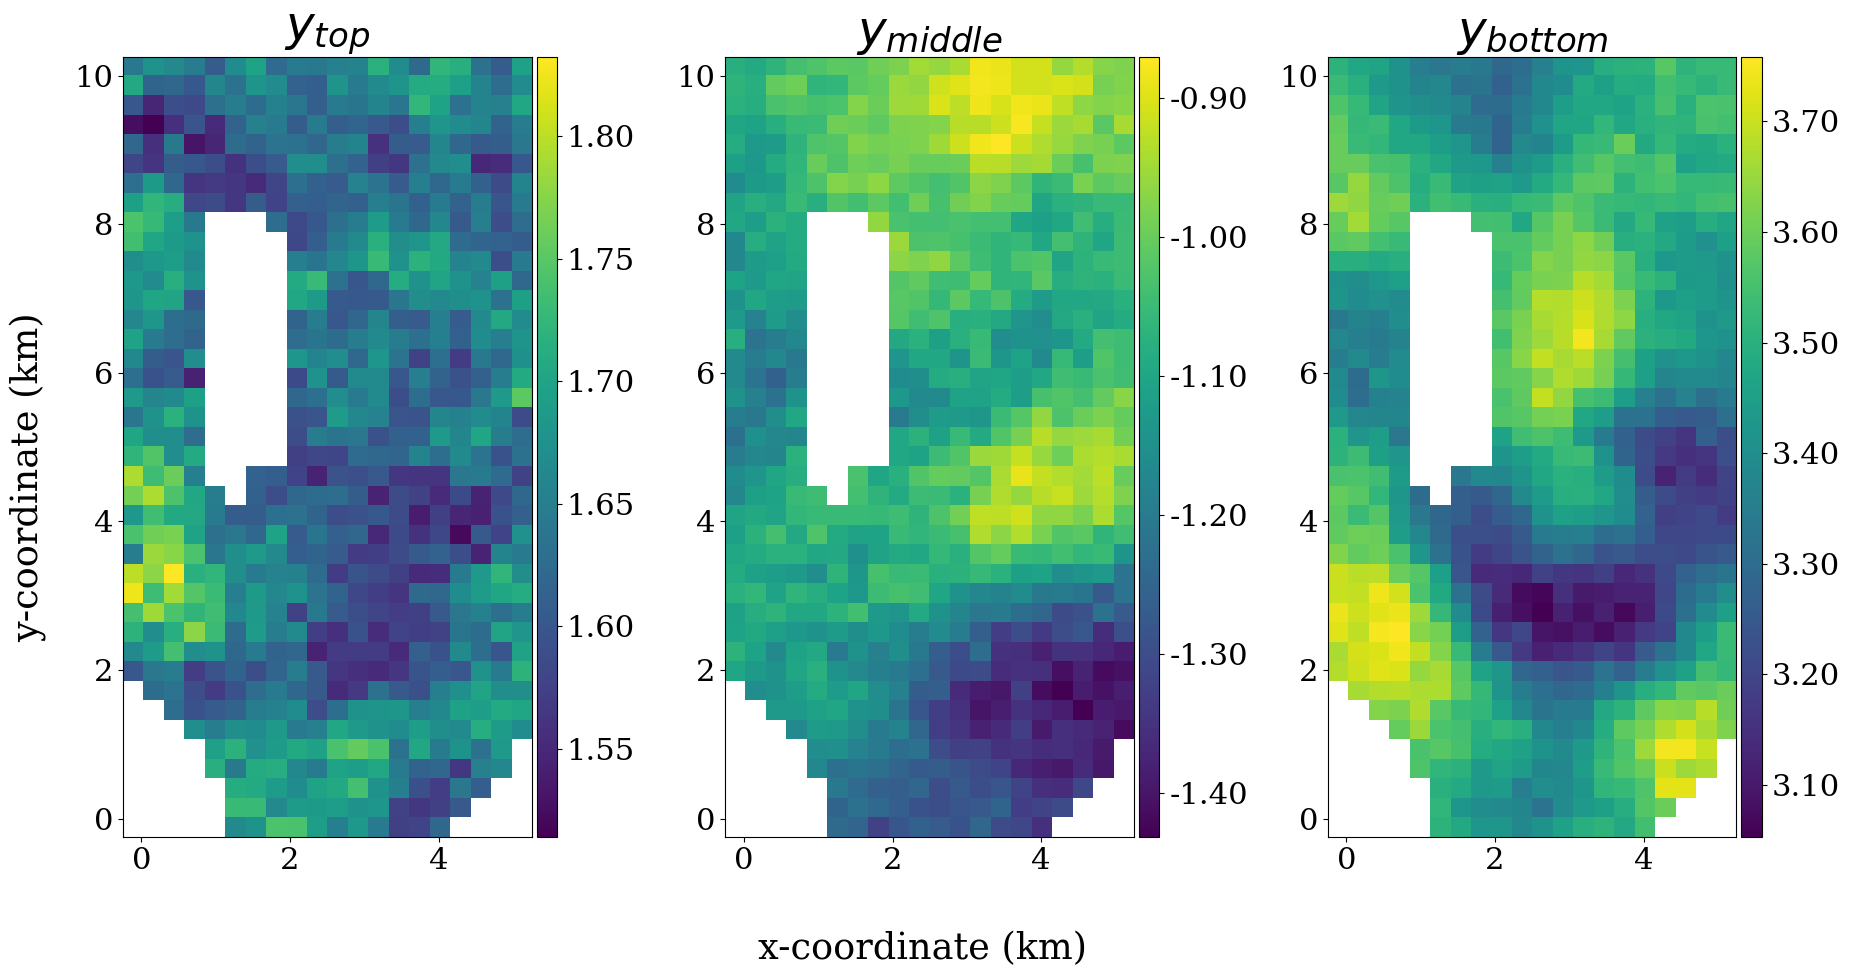

In [39]:
import matplotlib.ticker as tkr
Ntest=-1
# ymin = min(np.min(p_mean[:,Ntest][:706]),np.min(y_tempt[:,Ntest][:706]))
# ymax = max(np.max(p_mean[:,Ntest][:706]),np.max(y_tempt[:,Ntest][:706]))
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(p_mean[:,Ntest],0),extent=extent)
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][706:1412]),np.min(y_tempt[:,Ntest][706:1412]))
# ymax = max(np.max(p_mean[:,Ntest][706:1412]),np.max(y_tempt[:,Ntest][706:1412]))
layer2=ax2.imshow(mesh_recon_y(p_mean[:,Ntest],1),extent=extent)
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

# ymin = min(np.min(p_mean[:,Ntest][-706:]),np.min(y_tempt[:,Ntest][-706:]))
# ymax = max(np.max(p_mean[:,Ntest][-706:]),np.max(y_tempt[:,Ntest][-706:]))
layer3=ax3.imshow(mesh_recon_y(p_mean[:,Ntest],2),extent=extent)
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
plt.show()

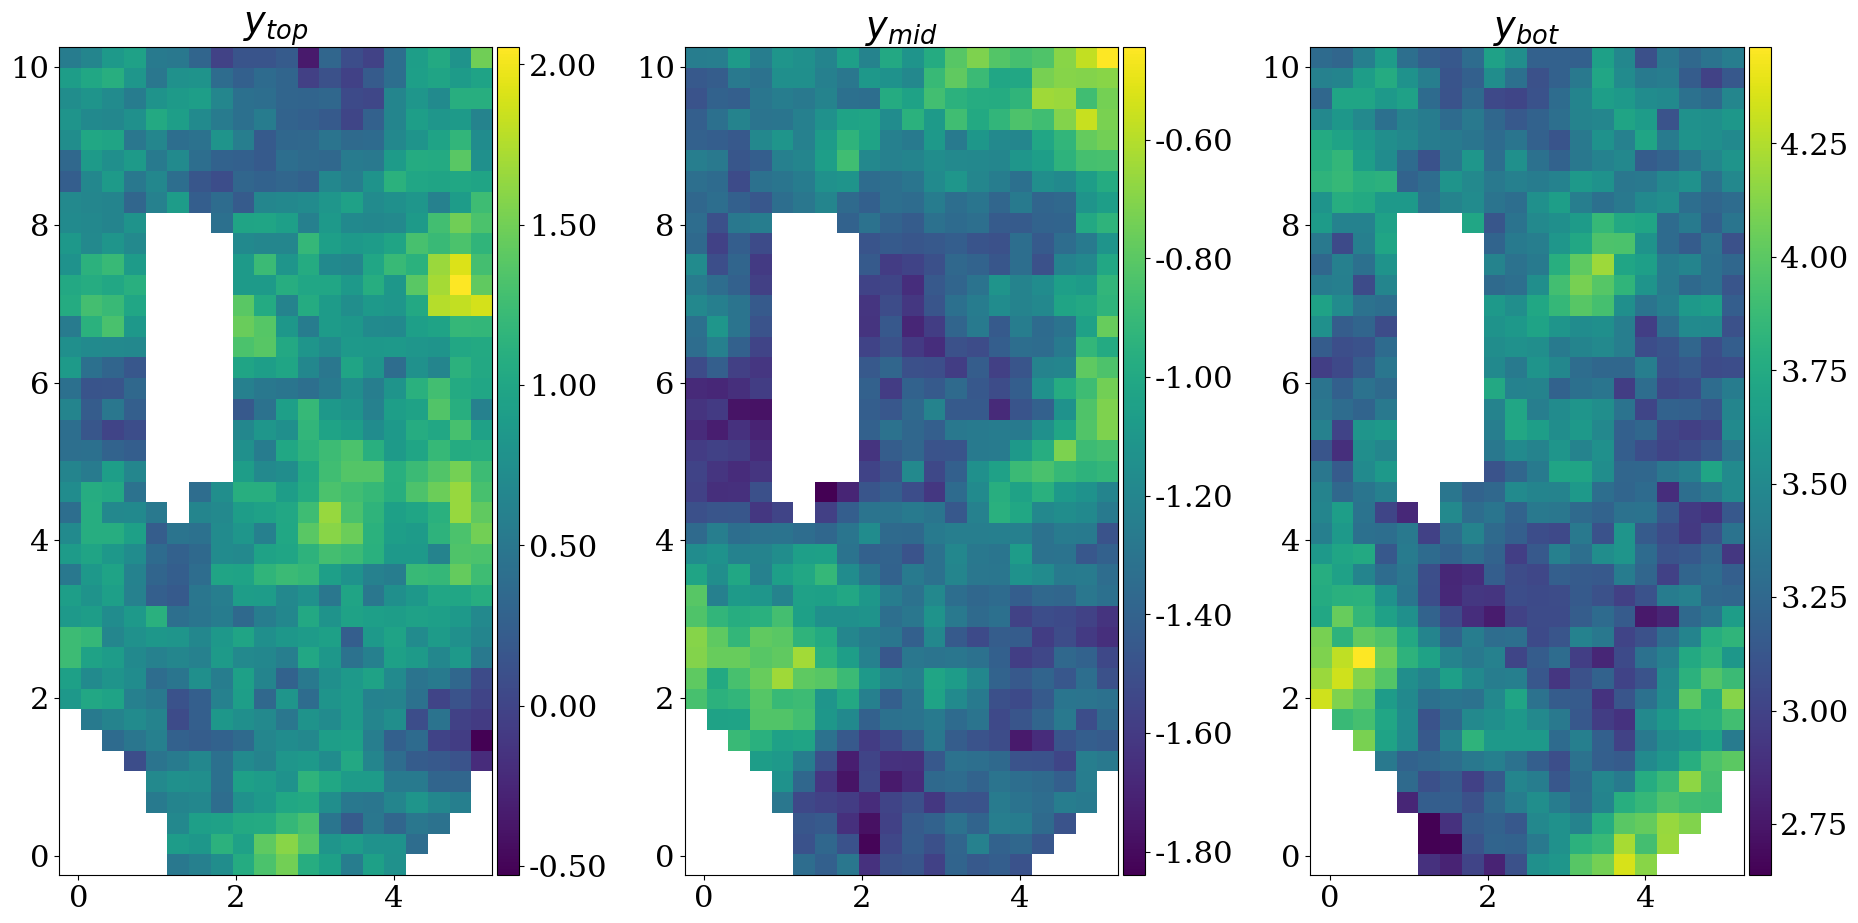

In [24]:
Ntest=-1
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(y_tempt[:,Ntest],0),extent=extent)
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold")

layer2=ax2.imshow(mesh_recon_y(y_tempt[:,Ntest],1),extent=extent)
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{mid}$', fontweight ="bold")

layer3=ax3.imshow(mesh_recon_y(y_tempt[:,Ntest],2),extent=extent)
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bot}$', fontweight ="bold")

f.tight_layout()
plt.show()

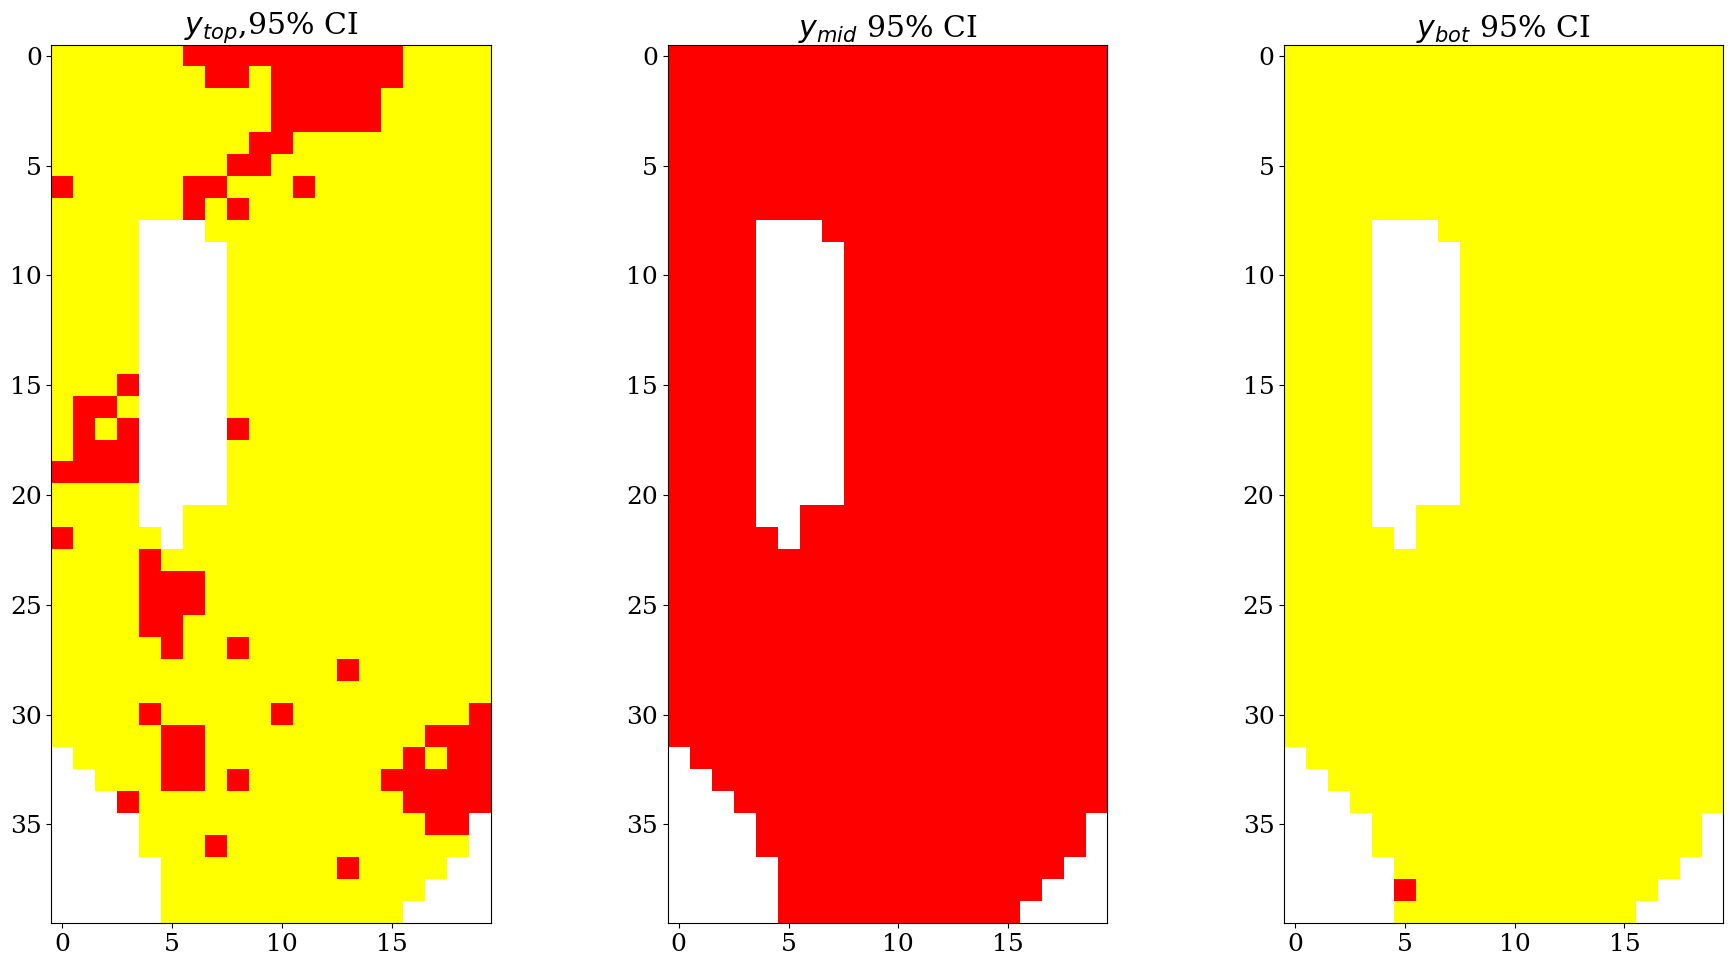

In [139]:
# plot CI95% and 99%
Nt=-1
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(CI95[:,Nt],0),cmap='autumn')
divider = make_axes_locatable(ax7)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI95, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$,95% CI')

conI95_2=ax8.imshow(mesh_recon_y(CI95[:,Nt],1),cmap='autumn')
divider = make_axes_locatable(ax8)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{mid}$ 95% CI')

conI95_3=ax9.imshow(mesh_recon_y(CI95[:,Nt],2),cmap='autumn')
divider = make_axes_locatable(ax9)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bot}$ 95% CI')

f.tight_layout()
plt.show()